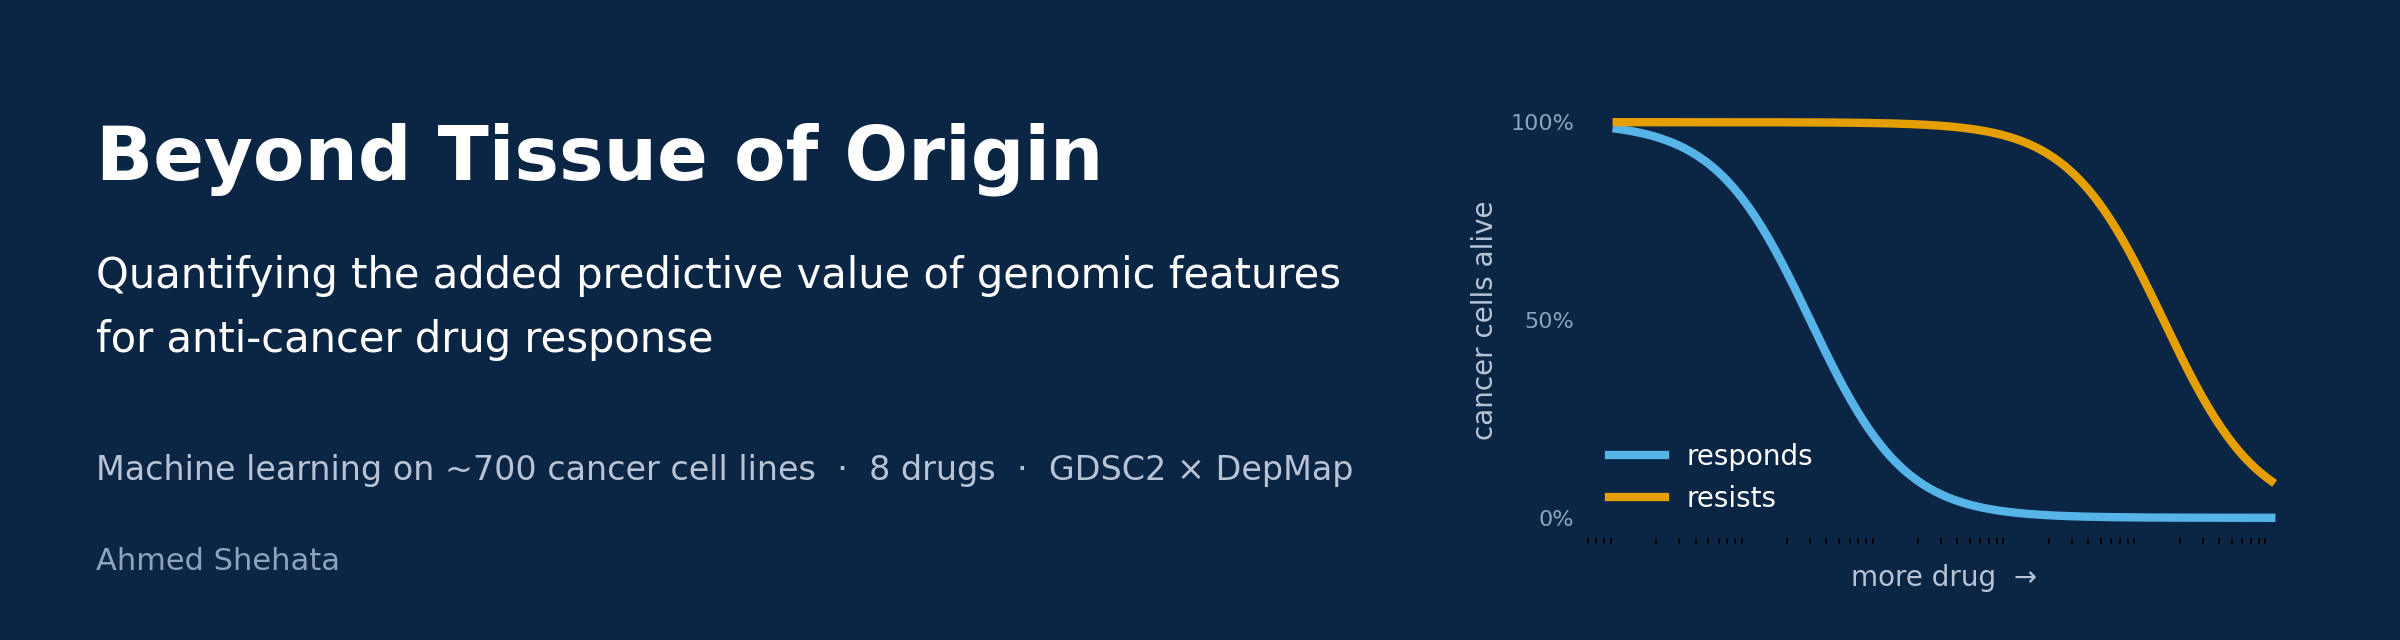

In [1]:
from IPython.display import Image, display
display(Image("images/banner.png", width=1000))

# Beyond Tissue of Origin: Quantifying the Added Predictive Value of Genomic Features for Anti-Cancer Drug Response

**A machine-learning study of 8 cancer drugs across ~700 cancer cell lines**, using the two largest public datasets for this question: [GDSC](https://www.cancerrxgene.org) (drug tests) and [DepMap](https://depmap.org) (cell genetics).

---

### Summary

Most cancer drugs only help a minority of the patients who receive them, and for most drugs there is no test that tells doctors in advance *who* that minority is. This project asks a simple question with a careful method:

> **If we read a cancer's genes, can we predict how well a specific drug will work on it, better than just knowing which organ the cancer came from?**

### Results at a glance

These were measured on ~140 cancer cell lines the models never saw during training.

| Drug | What it targets | Guess from organ alone | Best gene-based model | Do genes add real value? |
|---|---|:---:|:---:|:---:|
| Dabrafenib | *BRAF* gene (skin cancers) | 0.59 | **0.73** | Yes |
| Trametinib | same pathway as *BRAF* | 0.57 | **0.76** | Yes |
| Erlotinib | *EGFR* gene (lung cancers) | 0.36 | **0.63** | Yes |
| Alpelisib | *PIK3CA* gene (breast cancers) | 0.24 | **0.42** | Yes |
| Nutlin-3a | the *TP53* "guardian" gene | 0.43 | **0.75** | Yes |
| Venetoclax | *BCL2* (blood cancers) | 0.54 | **0.70** | Yes |
| Palbociclib | cell-division machinery | 0.60 | 0.64 | Not proven |
| Paclitaxel | classic chemotherapy | 0.32 | **0.56** | Yes |

<sub>Scores are correlations between predicted and real drug response (1.0 = perfect ranking, 0 = no better than chance). "Real value" means the improvement over the organ-only guess held up under a statistical check (95% confidence interval above zero).</sub>

**Three takeaways:**

1. **Genes improve the prediction for 7 of 8 drugs**, beyond what the cancer's organ of origin already tells you.
2. **The models rediscovered known biology on their own.** Without being told, they identified the textbook "warning-light" gene as the most important input for three of the drugs. For the chemotherapy drug, they found a pump that cancer cells use to push the drug back out.
3. **They also show where the approach fails**, for example when the key gene change is too rare in the data to learn from.

---

### How to read this notebook

| You'll see | What it's for |
|---|---|
| **In plain English** | The idea, explained with an everyday analogy. No biology or data-science background needed. |
| **What this shows** | The takeaway from the chart or table just above it. |
| **For the technical reader** (click to expand) | The design choices, the alternatives considered and why they were rejected. This is for data scientists reviewing the rigour. |

**Contents**

| # | Stage | Section |
|---|---|---|
| 1 | Problem framing | The problem · Key words |
| 2 | Data acquisition | Step 1 |
| 3 | Data cleaning and integration | Step 2 |
| 4 | Exploratory data analysis | Step 3 |
| 5 | Feature engineering | Step 4 |
| 6 | Validation design | Step 5 |
| 7 | Modelling and hyperparameter tuning | Step 6 |
| 8 | Evaluation | Step 7 |
| 9 | Interpretation | Step 8 |
| 10 | Reporting | Limitations · Conclusion · Decision log · References |
| A | Appendix: what was done at each stage | End of notebook |

## The problem

Imagine 100 patients with the same cancer, all given the same drug. Typically only a minority respond. The rest get the side effects, the cost and the lost months without the benefit. For a handful of drugs, doctors can already tell in advance who will respond, because a **genetic test** points to a specific fault in the cancer. The best-known example is melanoma (skin cancer) with a faulty *BRAF* gene, which is treated with a BRAF-blocking drug. For most drugs no such test exists yet.

> **In plain English:** a cancer is the body's own cells with faults in their instruction manual (their **genes**). Different cancers have different faults. Some drugs work by attacking a specific fault, so they only work on cancers that *have* that fault. If we can read the faults, maybe we can predict which drug fits which cancer, like matching a key to a lock.

**Why cell lines?** We can't give 8 drugs to the same patient to see which works. Instead, researchers use **cancer cell lines**: cancer cells taken from patients and grown in the lab. They can be tested against hundreds of drugs side by side. There are about 1,000 of them, from lung, skin, blood, breast and other cancers. Each one is a **stand-in patient**.

**Who would use this kind of analysis:**

- **Cancer researchers**, looking for new genetic tests.
- **Drug companies**, deciding which gene–drug pairs are worth a clinical trial.
- **Health economists**, judging whether "test first, then treat" is worth paying for.

The 8-step plan below is the map for the rest of this notebook.

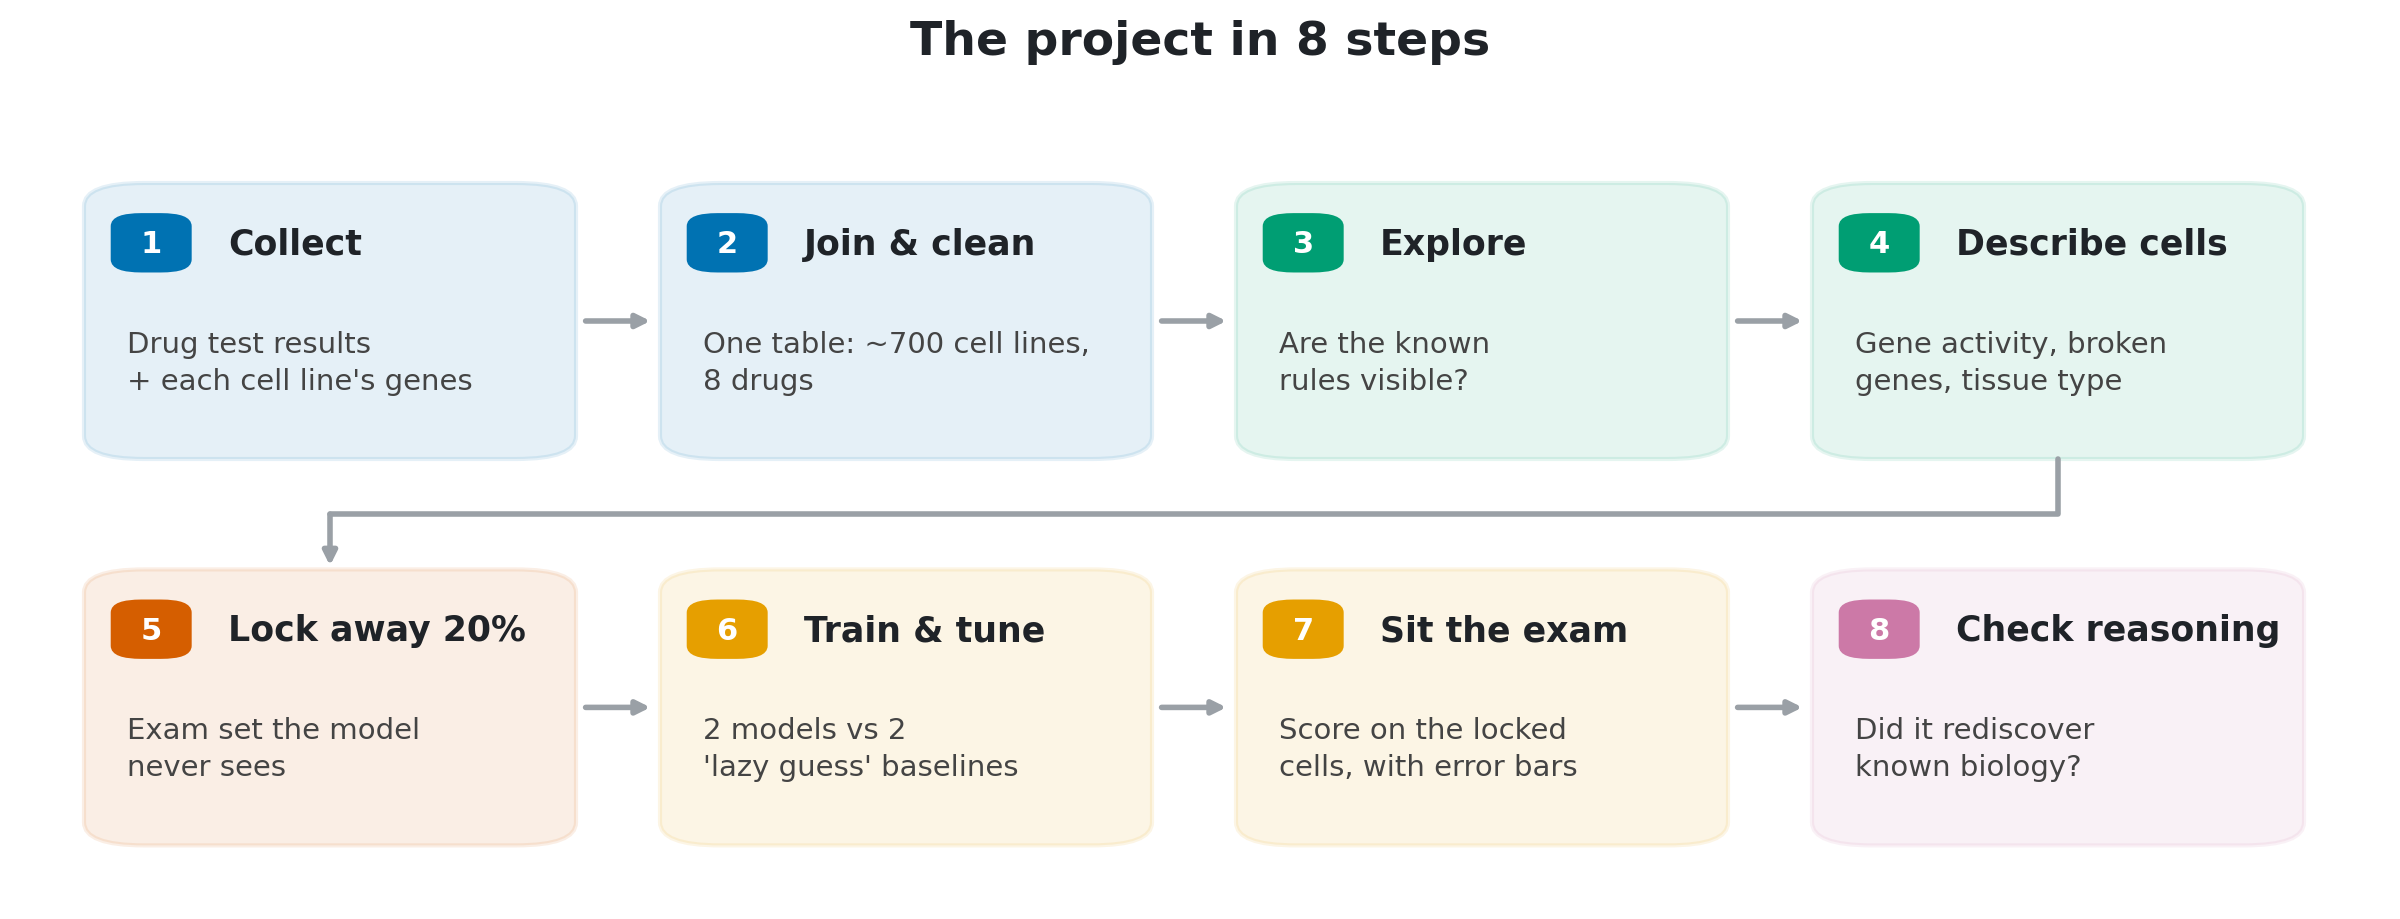

In [2]:
display(Image("images/pipeline.png", width=1000))

## Key words (the only biology you need)

| Word | Meaning | Analogy |
|---|---|---|
| **Gene** | A section of a cell's DNA with the instructions for one part of the cell's machinery | One page of an instruction manual |
| **Mutation** | A change in a gene that alters how its part works: sometimes switched off, sometimes jammed "on" | A typo in the manual that breaks the part, or jams the accelerator |
| **Gene activity** (*expression*) | How strongly a gene is being used right now | A volume knob: the same page can be read quietly or loudly |
| **Cell line** | Cancer cells from one patient, grown in the lab | A stand-in patient |
| **IC50** | The drug dose that kills half the cancer cells | Lower IC50 = the drug works better (explained with a picture in Step 1) |
| **Biomarker** | A measurable feature that predicts whether a drug will work | A warning light that says "this drug should work here" |
| **Tissue** | The organ the cancer came from (lung, skin, blood…) | The "type" of cancer |

Gene names such as *BRAF*, *TP53* or *BCL2* are just names, like part numbers. You don't need to know what they do. Where it matters, the notebook says.

## Step 0 · Setup

The tools used are standard, widely used Python libraries for data analysis and machine learning. A fixed "random seed" makes every random choice repeatable: anyone who runs this notebook gets exactly the same numbers.

<details>
<summary><b>For the technical reader</b>: libraries, versions, runtime</summary>

- **Libraries:**
  - pandas and numpy for data handling;
  - scikit-learn for pipelines, ridge regression, cross-validation and metrics;
  - LightGBM for gradient-boosted trees;
  - SHAP for explanations;
  - scipy for statistics;
  - matplotlib and seaborn for plots.
- **Tested with:** Python 3.11, pandas 3.0, numpy 2.4, scikit-learn 1.8, lightgbm 4.7, shap 0.51, scipy 1.17, matplotlib 3.10, seaborn 0.13, openpyxl 3.1 (see `requirements.txt`).
- **Seed:** `SEED = 42` is used for every split, model and bootstrap. The value is arbitrary; what matters is that it is fixed.
- **Runtime:** about 45 minutes on a 2-core machine. Nearly all of it is the model tuning in Step 6; a typical laptop is faster.
- **Palette:** Okabe–Ito (colour-blind-safe) in every chart.
</details>

In [3]:
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message=".*IProgress.*")     # cosmetic notebook-widget warning from shap's tqdm
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, roc_auc_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import lightgbm as lgb
import shap

SEED = 42
np.random.seed(SEED)

# ---- One consistent, colour-blind-safe visual style (Okabe-Ito palette) ----
BLUE, ORANGE, GREEN, VERMILION, PURPLE, SKY, GREY, INK = (
    "#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#9AA0A6", "#1F2328")
sns.set_theme(style="whitegrid", palette=[BLUE, ORANGE, GREEN, VERMILION, PURPLE, SKY])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
                     "axes.labelsize": 11, "axes.edgecolor": "#BBBBBB", "grid.color": "#EEEEEE"})
pd.set_option("display.max_colwidth", None)   # show full text in tables
FIG_DIR = Path("images")          # key figures are also saved here for the README
FIG_DIR.mkdir(exist_ok=True)


def save(fig, name):
    '''Save a figure to images/ (used by the README) at print quality.'''
    fig.savefig(FIG_DIR / name, dpi=160, bbox_inches="tight", facecolor="white")


import sklearn, scipy
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | "
      f"lightgbm {lgb.__version__} | shap {shap.__version__} | scipy {scipy.__version__}")

pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0 | lightgbm 4.7.0 | shap 0.51.0 | scipy 1.17.1


## Step 1 · Data acquisition: the two datasets

Two public datasets, produced by two of the world's leading cancer-research institutes:

| Dataset | Who made it | What it tells us |
|---|---|---|
| **GDSC**: *Genomics of Drug Sensitivity in Cancer* | Wellcome Sanger Institute (UK) | **The drug test results.** Hundreds of drugs tested on ~1,000 cell lines. For each pair, the dose needed to kill half the cells (IC50). |
| **DepMap**: *Cancer Dependency Map* | Broad Institute of MIT & Harvard (US) | **Each cell line's genetics.** Which genes have mutations, how active each of ~19,000 genes is, and which organ it came from. |

> **In plain English:** GDSC is each stand-in patient's **report card** (how they reacted to each drug). DepMap is their **ID card** (their genetic make-up). The whole project is about learning the link between the two.

**What IC50 means.** Each cell line is exposed to a drug at a range of doses, and the lab counts how many cells survive. The picture below shows three imaginary cell lines. The dose that kills half the cells is the **IC50**. Line A needs very little drug, so it *responds*. Line C barely notices it, so it *resists*.

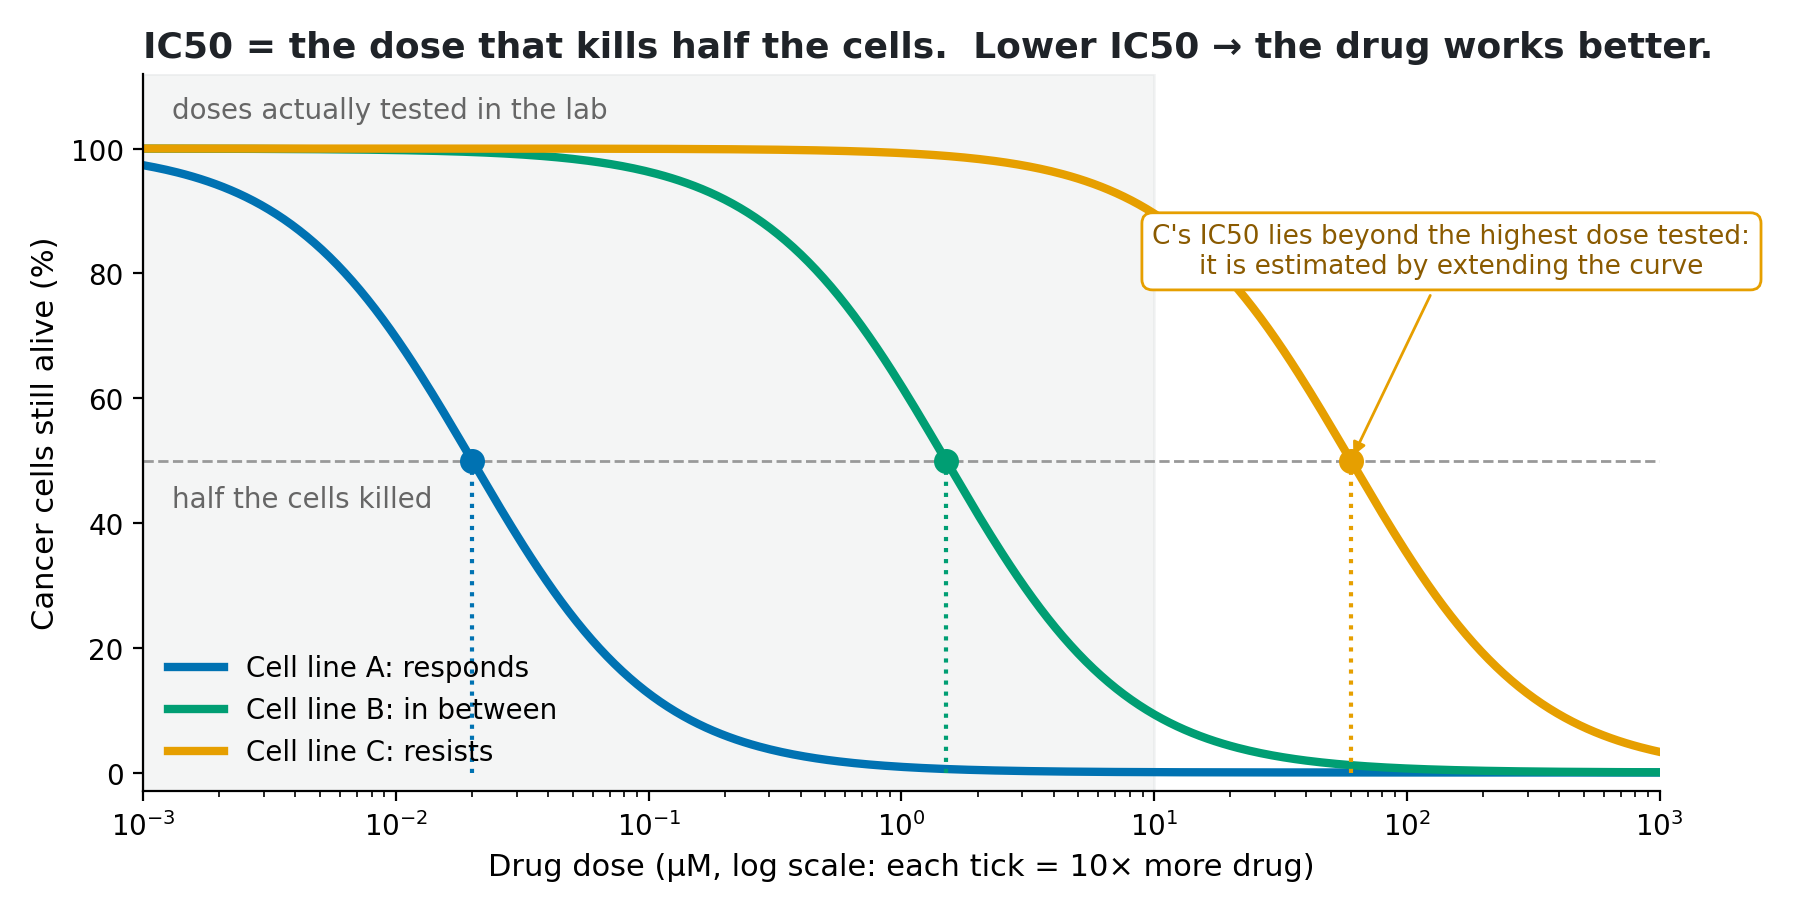

In [4]:
display(Image("images/ic50_explained.png", width=800))

Because IC50 values span huge ranges (from a few nanomoles to many micromoles, a factor of 10,000 or more), scientists work with its **logarithm**, **ln IC50**, the same way engineers use decibels for sound. A difference of 1 in ln IC50 means the drug is about 2.7× more (or less) potent. **Lower ln IC50 = more sensitive.**

The picture below shows how the two datasets fit together.

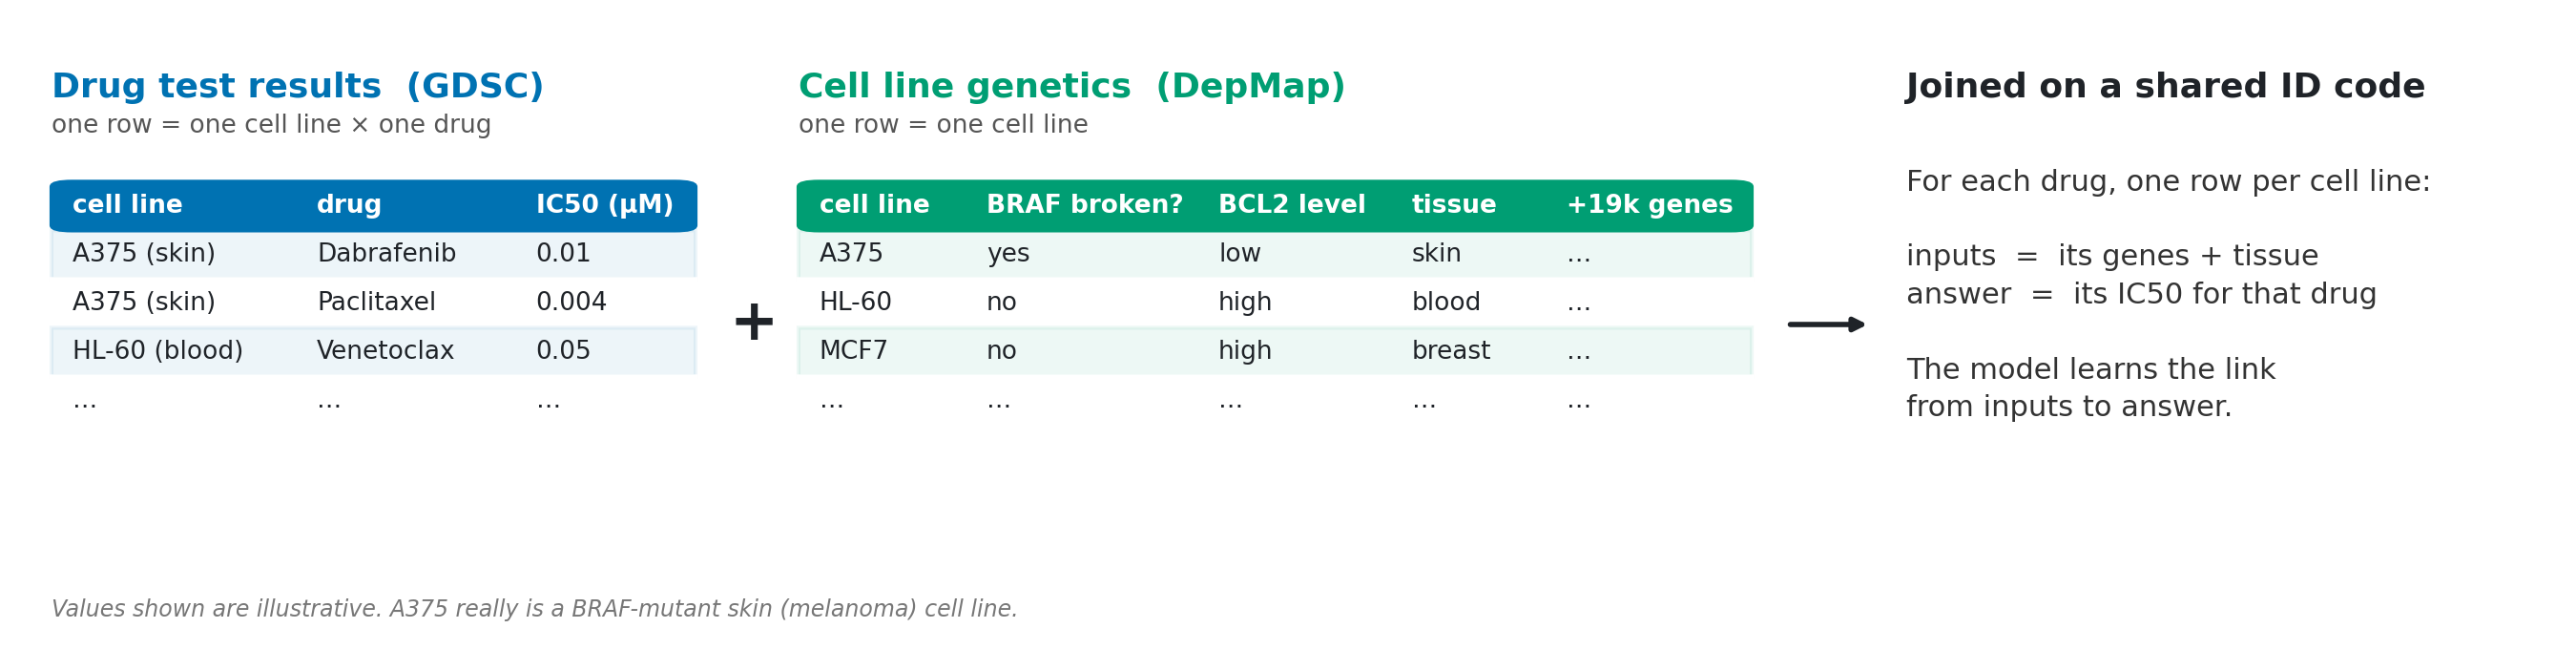

In [5]:
display(Image("images/data_join.png", width=1000))

To run this notebook, download the five files below and put them in a folder called `data/` next to it. Both sources are free.

| File | Where to get it |
|---|---|
| `GDSC2_fitted_dose_response_27Oct23.xlsx` | [cancerrxgene.org](https://www.cancerrxgene.org/downloads/bulk_download) or [Cell Model Passports](https://cellmodelpassports.sanger.ac.uk/downloads) (GDSC2, Release 8.5) |
| `Model.csv`, `OmicsExpressionTPMLogp1HumanProteinCodingGenes.csv`, `OmicsSomaticMutationsMatrixDamaging.csv`, `OmicsSomaticMutationsMatrixHotspot.csv` | [depmap.org → Downloads](https://depmap.org/portal/download/all/) (latest *DepMap Public* release) |

<details>
<summary><b>For the technical reader</b>: versions, and why copy number is left out</summary>

- **GDSC2 Release 8.5 (Oct 2023).** This is the latest release, and it corrects a curve-fitting issue affecting 39 GDSC2 compounds. Its `LN_IC50` is the natural log of the fitted IC50 in µM.
- **DepMap Public:** expression is log2(TPM+1) for protein-coding genes. The mutation matrices are gene-level counts of damaging and hotspot mutations.
- **Multiple profiles per cell line:** some lines were sequenced more than once. We keep the row flagged `IsDefaultEntryForModel == "Yes"`, following DepMap's own guidance.
- **Copy number is deliberately excluded.** Drug-relevant copy-number events largely act through expression (e.g. *ERBB2* amplification shows up as very high *ERBB2* expression). Adding ~19k more columns for ~700 samples would cost interpretability for a small expected gain. It is listed as a next step.
</details>

In [6]:
DATA_DIR = Path("data")
DEPMAP_RELEASE = "DepMap Public (latest release, downloaded 26 Sep 2026)"


def load_depmap(filename, genes=None):
    '''Load a DepMap cell-line x gene table, keeping each cell line's default profile.

    filename: file in DATA_DIR; genes: optional list of gene names to keep (default: all).
    Returns a table indexed by DepMap cell-line ID, with columns renamed 'TP53 (7157)' -> 'TP53'.
    '''
    path = DATA_DIR / filename
    header = pd.read_csv(path, nrows=0).columns
    meta = [c for c in header if c.startswith("Unnamed") or c in
            ("SequencingID", "ModelID", "ModelConditionID", "IsDefaultEntryForModel", "IsDefaultEntryForMC")]
    gene_cols = [c for c in header if c not in meta]
    if genes is not None:
        gene_cols = [c for c in gene_cols if c.split(" (")[0] in set(genes)]
    df = pd.read_csv(path, usecols=meta + gene_cols)
    if "IsDefaultEntryForModel" in df.columns:
        df = df[df["IsDefaultEntryForModel"] == "Yes"]
    df = df.drop_duplicates("ModelID").set_index("ModelID")[gene_cols]
    df.columns = [c.split(" (")[0] for c in df.columns]
    return df.loc[:, ~df.columns.duplicated()]


t0 = time.time()
gdsc = pd.read_excel(DATA_DIR / "GDSC2_fitted_dose_response_27Oct23.xlsx")
models = pd.read_csv(DATA_DIR / "Model.csv", low_memory=False)
expression = load_depmap("OmicsExpressionTPMLogp1HumanProteinCodingGenes.csv").astype("float32")

print(f"Drug tests (GDSC2):   {gdsc.shape[0]:,} results  = {gdsc['CELL_LINE_NAME'].nunique()} cell lines x "
      f"{gdsc['DRUG_ID'].nunique()} drugs")
print(f"Cell lines (DepMap):  {models.shape[0]:,} described")
print(f"Gene activity table:  {expression.shape[0]:,} cell lines x {expression.shape[1]:,} genes")
print(f"[loaded in {time.time() - t0:.0f}s]")

Drug tests (GDSC2):   242,036 results  = 969 cell lines x 295 drugs
Cell lines (DepMap):  2,154 described
Gene activity table:  1,719 cell lines x 19,215 genes
[loaded in 48s]


## Step 2 · Data cleaning and integration: joining the datasets and choosing the drugs

**Joining.** The two datasets come from different institutes, so we have to match each cell line's report card to its ID card. We match on a shared **ID code**, not on the cell line's name, because names are written inconsistently: "NCI-H1299" in one file is "NCIH1299" in another. Matching by name would silently drop or mix up cell lines. We then keep only cell lines that have *both* a full genetic profile and drug results. That leaves about 700.

**Choosing 8 drugs.** We deliberately picked drugs where science already knows the "rule" (the biomarker). That gives us an **answer key**: if the model is sound, it should rediscover these rules without being told. It is the same principle as testing a new measuring instrument on a reference sample of known value first.

| Drug | Type | Known rule (the answer key) | Why it's in the study |
|---|---|---|---|
| **Dabrafenib** | Targeted drug | Faulty *BRAF* gene → **responds** | The classic example, used in skin cancer |
| **Trametinib** | Targeted drug | Faults in *BRAF* or related genes → responds | Same pathway, less clear-cut rule |
| **Erlotinib** | Targeted drug | Faulty *EGFR* gene → responds | Real rule, but the fault is **rare** in this data: a hard case |
| **Alpelisib** | Targeted drug | Faulty *PIK3CA* gene → responds | Approved rule, weaker effect |
| **Nutlin-3a** | Targeted drug | Faulty *TP53* gene → **resists** | A rule that predicts *failure* |
| **Venetoclax** | Targeted drug | *BCL2* gene very active → responds | Rule based on gene *activity*, not a mutation |
| **Palbociclib** | Targeted drug | Missing *RB1* gene → resists | Weak rule |
| **Paclitaxel** | Chemotherapy | **None known** | The **control**: no single gene should dominate |

<details>
<summary><b>For the technical reader</b>: join key, edge cases, drug selection</summary>

- **Join:** GDSC `SANGER_MODEL_ID` → DepMap `SangerModelID`, a curated cross-reference maintained by both resources.
  - *Alternative considered:* joining on cell-line names. *Why not:* inconsistent formatting causes silent mismatches.
- **One ambiguous ID:** a single Sanger ID maps to two DepMap models, a parental line and its subline (NCI-H322 / NCI-H322M). The first entry is kept.
- **Missing omics:** lines lacking expression or mutation data are dropped, not imputed. Imputing an entire genome would mean fabricating the input.
- **Selection bias, acknowledged:** drugs were chosen *because* they have known biomarkers, so they act as positive controls, plus one negative control (paclitaxel). Performance on a random GDSC drug would likely be lower. This is stated again in the Limitations.
  - *Alternative considered:* modelling all ~290 GDSC2 drugs. *Why not:* results could not be checked against an answer key. It is listed as a next step.
</details>

In [7]:
DRUGS = {  # GDSC2 drug ID -> name
    1373: "Dabrafenib", 1372: "Trametinib", 1168: "Erlotinib", 1560: "Alpelisib",
    1047: "Nutlin-3a", 1909: "Venetoclax", 1054: "Palbociclib", 1080: "Paclitaxel"}

# ~100 widely studied cancer "driver" genes, hand-picked from the COSMIC Cancer Gene Census.
DRIVER_GENES = [
    "TP53", "KRAS", "NRAS", "HRAS", "BRAF", "PIK3CA", "PIK3R1", "PTEN", "AKT1", "EGFR", "ERBB2", "ERBB3",
    "MET", "ALK", "ROS1", "RET", "FGFR1", "FGFR2", "FGFR3", "KIT", "PDGFRA", "FLT3", "JAK1", "JAK2", "ABL1",
    "MYC", "CCND1", "CDK4", "CDK6", "CDKN2A", "CDKN2B", "RB1", "MDM2", "APC", "CTNNB1", "AXIN1", "SMAD4",
    "TGFBR2", "NOTCH1", "NOTCH2", "FBXW7", "KEAP1", "NFE2L2", "STK11", "NF1", "NF2", "TSC1", "TSC2", "MTOR",
    "ARID1A", "ARID1B", "ARID2", "SMARCA4", "SMARCB1", "PBRM1", "KMT2C", "KMT2D", "KDM6A", "SETD2", "BAP1",
    "CREBBP", "EP300", "EZH2", "DNMT3A", "TET2", "IDH1", "IDH2", "ATM", "ATR", "BRCA1", "BRCA2", "PALB2",
    "CHEK2", "MLH1", "MSH2", "MSH6", "POLE", "VHL", "WT1", "GATA3", "FOXA1", "ESR1", "AR", "SPOP", "MAP2K1",
    "MAP2K4", "MAP3K1", "CIC", "RUNX1", "NPM1", "U2AF1", "SF3B1", "ASXL1", "BCOR", "STAG2", "CASP8", "B2M",
    "RNF43", "GNAQ", "GNA11", "GNAS", "CDH1", "FAT1"]

# A gene counts as "mutated" if it has a damaging (switches it off) OR a hotspot (jams it on) mutation.
damaging = load_depmap("OmicsSomaticMutationsMatrixDamaging.csv", DRIVER_GENES)
hotspot = load_depmap("OmicsSomaticMutationsMatrixHotspot.csv", DRIVER_GENES)
lines_with_mut = damaging.index.intersection(hotspot.index)
mutated = ((damaging.loc[lines_with_mut].reindex(columns=DRIVER_GENES).fillna(0) > 0)
           | (hotspot.loc[lines_with_mut].reindex(columns=DRIVER_GENES).fillna(0) > 0)).astype(int)

# Join the drug results to the genetics on the shared ID code
sanger_to_depmap = (models.dropna(subset=["SangerModelID"]).drop_duplicates("SangerModelID")
                    .set_index("SangerModelID")["ModelID"])
gdsc["ModelID"] = gdsc["SANGER_MODEL_ID"].map(sanger_to_depmap)
has_omics = gdsc["ModelID"].isin(expression.index) & gdsc["ModelID"].isin(mutated.index)

response = gdsc[has_omics & gdsc["DRUG_ID"].isin(DRUGS)].copy()
response["drug"] = response["DRUG_ID"].map(DRUGS)
lineage = models.set_index("ModelID")["OncotreeLineage"].fillna("Unknown")

n_matched = gdsc.dropna(subset=["ModelID"])["CELL_LINE_NAME"].nunique()
print(f"Cell lines matched between the two datasets:   {n_matched} of {gdsc['CELL_LINE_NAME'].nunique()}")
print(f"...with a complete genetic profile:             {gdsc.loc[has_omics, 'ModelID'].nunique()}")
(response.groupby("drug")
 .agg(**{"cell lines tested": ("ModelID", "nunique"), "drug target (GDSC label)": ("PUTATIVE_TARGET", "first"),
         "highest dose tested (µM)": ("MAX_CONC", "first")})
 .reindex(DRUGS.values()))

Cell lines matched between the two datasets:   967 of 969
...with a complete genetic profile:             716


,cell lines tested,drug target (GDSC label),highest dose tested (µM)
drug,,,
Dabrafenib,705,BRAF,10.00
Trametinib,714,"MEK1, MEK2",1.00
Erlotinib,704,EGFR,2.00
Alpelisib,713,PI3Kalpha,5.00
Nutlin-3a,715,MDM2,10.00
Venetoclax,707,BCL2,1.00
Palbociclib,715,"CDK4, CDK6",10.00
Paclitaxel,707,Microtubule stabiliser,0.01


## Step 3 · Exploratory data analysis (EDA)

Before building anything, we look at the raw data and ask three questions:

1. How does each drug's effect vary across cell lines?
2. Are the known rules (the answer key) visible in the raw numbers?
3. How much does the organ of origin alone explain?

> **In plain English:** before building a predictive model of a machine, an engineer first plots the raw measurements. If the signal isn't in the data, no model will conjure it. If it is, we know what "good" should look like.

### 3.1 How much does each drug's effect vary?

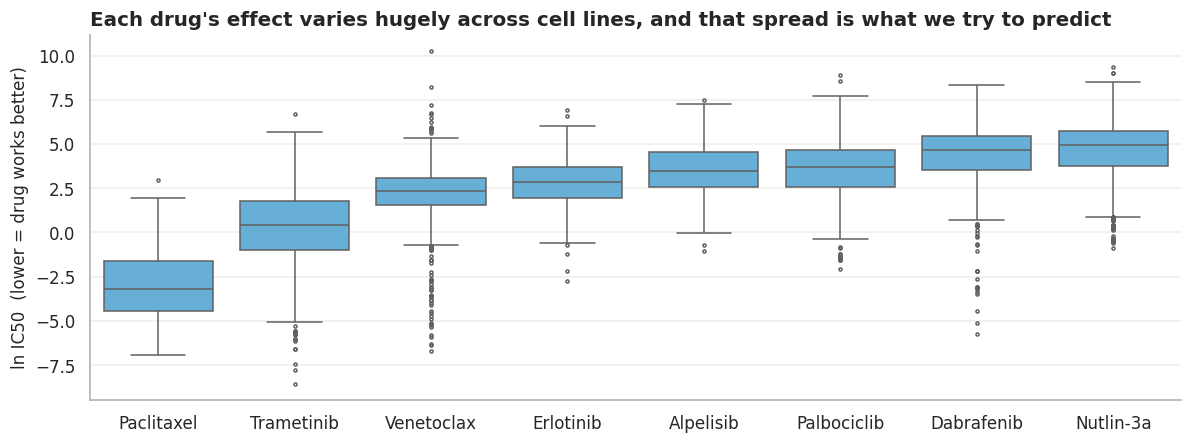

In [8]:
order = response.groupby("drug")["LN_IC50"].median().sort_values().index
fig, ax = plt.subplots(figsize=(11, 4.2))
sns.boxplot(data=response, x="drug", y="LN_IC50", order=order, color=SKY, fliersize=2, linewidth=1, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("ln IC50  (lower = drug works better)")
ax.set_title("Each drug's effect varies hugely across cell lines, and that spread is what we try to predict")
plt.tight_layout(); plt.show()

> **What this shows:**
>
> - **Drugs differ in strength.** Paclitaxel, the chemotherapy, is by far the most potent: its typical IC50 is about 40 nanomolar. The targeted drugs need much more.
> - **Within every drug, the spread is enormous.** Between the most and least sensitive cell lines (ignoring the extreme 5% at each end), the dose needed differs by **80× to over 1,000×**. The model's job is to explain that spread: *which* cell lines respond.
> - **Most lines resist the targeted drugs.** For 6 of the 8 drugs, even the highest dose tested fails to kill half the cells in 82–91% of cell lines. That is normal for targeted drugs, which only work on the minority with the right fault. So the task is mainly to **find the minority that responds**.

<details>
<summary><b>For the technical reader</b>: extrapolated IC50s</summary>

When a cell line never reaches 50% kill within the tested range, GDSC's curve fit places its IC50 *beyond* the highest dose, which makes it an extrapolation (line C in the Step 1 picture).

**Decision:** keep these values as released.

- *Alternative considered:* dropping them. *Why not:* they are exactly the resistant lines, and removing them would make every drug look better than it is.
- *Alternative considered:* capping them, or modelling AUC instead. *Why not:* both are reasonable robustness checks, listed in the Limitations. ln IC50 as released is the field's most common and most interpretable target.
</details>

### 3.2 Is the answer key visible in the raw data?

For each drug, we split the cell lines into those *with* and *without* the known fault and compare their drug response. For venetoclax, whose rule is about a gene's *activity* rather than a fault, we plot activity against response instead.

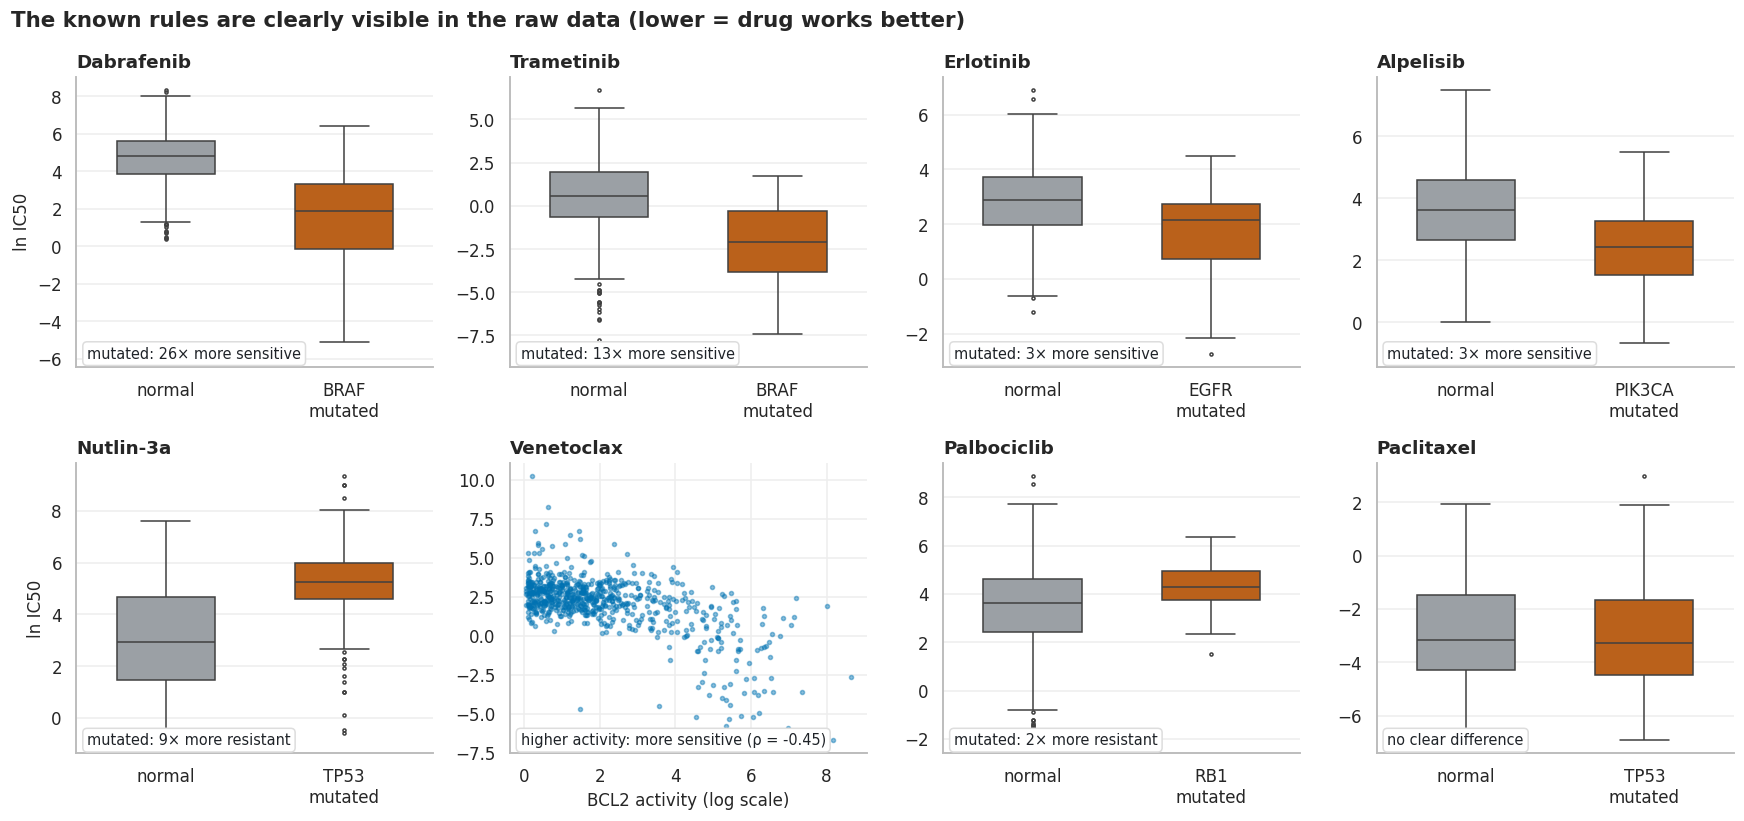

,answer-key rule,lines with the mutation,effect in the data,p-value,expected
drug,,,,,
Dabrafenib,BRAF mutation,66 of 705,mutated: 26× more sensitive,6e-24,lower
Trametinib,BRAF mutation,68 of 714,mutated: 13× more sensitive,1e-15,lower
Erlotinib,EGFR mutation,19 of 704,mutated: 3× more sensitive,3e-03,lower
Alpelisib,PIK3CA mutation,80 of 713,mutated: 3× more sensitive,2e-11,lower
Nutlin-3a,TP53 mutation,493 of 715,mutated: 9× more resistant,6e-42,higher
Venetoclax,BCL2 activity,n = 707,higher activity: more sensitive (ρ = -0.45),2e-37,lower
Palbociclib,RB1 mutation,68 of 715,mutated: 2× more resistant,7e-06,higher
Paclitaxel,TP53 mutation,487 of 707,no clear difference,4e-01,none expected


In [9]:
# The answer key: (type of feature, gene, expected effect of the feature on ln IC50)
BIOMARKERS = {
    "Dabrafenib": ("mut", "BRAF", "lower"),   "Trametinib": ("mut", "BRAF", "lower"),
    "Erlotinib": ("mut", "EGFR", "lower"),    "Alpelisib": ("mut", "PIK3CA", "lower"),
    "Nutlin-3a": ("mut", "TP53", "higher"),   "Venetoclax": ("expr", "BCL2", "lower"),
    "Palbociclib": ("mut", "RB1", "higher"),  "Paclitaxel": ("mut", "TP53", "none expected")}

fig, axes = plt.subplots(2, 4, figsize=(16, 7.6))
rows = []
for ax, (drug, (kind, gene, expected)) in zip(axes.flat, BIOMARKERS.items()):
    d = response[response["drug"] == drug]
    y = d["LN_IC50"].values
    if kind == "mut":
        is_mut = mutated.loc[d["ModelID"], gene].values == 1
        labels = np.where(is_mut, f"{gene}\nmutated", "normal")
        sns.boxplot(x=labels, y=y, order=["normal", f"{gene}\nmutated"], hue=labels,
                    hue_order=["normal", f"{gene}\nmutated"], palette=[GREY, VERMILION], legend=False,
                    fliersize=2, linewidth=1, width=0.55, ax=ax)
        diff = y[is_mut].mean() - y[~is_mut].mean()
        p = stats.mannwhitneyu(y[is_mut], y[~is_mut]).pvalue
        fold = np.exp(abs(diff))
        if p >= 0.05:
            verdict = "no clear difference"
        else:
            verdict = f"mutated: {fold:.0f}× more {'sensitive' if diff < 0 else 'resistant'}"
        rows.append({"drug": drug, "answer-key rule": f"{gene} mutation", "lines with the mutation": f"{is_mut.sum()} of {len(d)}",
                     "effect in the data": verdict, "p-value": p, "expected": expected})
        ax.set_xlabel("")
    else:
        x = expression.loc[d["ModelID"], gene].values
        ax.scatter(x, y, s=7, alpha=0.45, color=BLUE)
        rho, p = stats.spearmanr(x, y)
        verdict = f"higher activity: more sensitive (ρ = {rho:.2f})"
        rows.append({"drug": drug, "answer-key rule": f"{gene} activity", "lines with the mutation": f"n = {len(d)}",
                     "effect in the data": verdict, "p-value": p, "expected": expected})
        ax.set_xlabel(f"{gene} activity (log scale)")
    ax.set_title(drug, fontsize=12)
    ax.text(0.03, 0.03, verdict, transform=ax.transAxes, fontsize=9.5, color=INK,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#DDDDDD"))
    ax.set_ylabel("ln IC50" if ax in axes[:, 0] else "")
fig.suptitle("The known rules are clearly visible in the raw data (lower = drug works better)",
             x=0.01, ha="left", fontsize=14, weight="bold")
plt.tight_layout(); save(fig, "biomarkers_raw.png"); plt.show()

biomarker_raw = pd.DataFrame(rows).set_index("drug")
biomarker_raw.style.format({"p-value": "{:.0e}"})

> **What this shows:**
>
> - **All 7 known rules show up clearly in the raw data**, all at p < 0.01, meaning they are very unlikely to be chance. For example:
>   - cell lines with a *BRAF* mutation are about **26× more sensitive** to dabrafenib;
>   - lines with a *TP53* mutation are about **9× more resistant** to Nutlin-3a.
> - **The control behaves as expected:** paclitaxel shows **no difference** by *TP53* status (p = 0.36).
> - **Erlotinib's key mutation is rare:** only **19 of 704** cell lines carry the *EGFR* mutation. That will matter later.
>
> So the signal is there. The real question is whether a model can **find it by itself** among ~2,000 genes, without being told where to look.

### 3.3 How much does the organ of origin explain on its own?

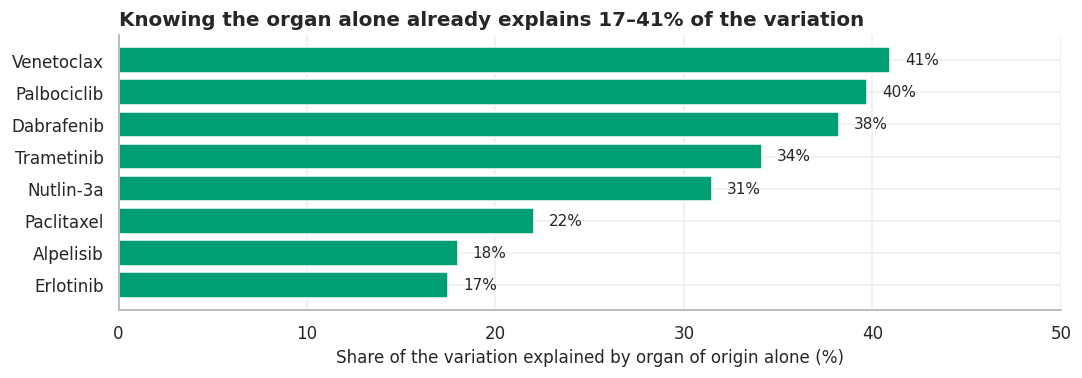

In [10]:
tissue_r2 = {}
for drug in DRUGS.values():
    d = response[response["drug"] == drug].assign(tissue=lambda x: x["ModelID"].map(lineage))
    fitted = d.groupby("tissue")["LN_IC50"].transform("mean")
    tissue_r2[drug] = 1 - ((d["LN_IC50"] - fitted) ** 2).sum() / ((d["LN_IC50"] - d["LN_IC50"].mean()) ** 2).sum()
tissue_r2 = pd.Series(tissue_r2).sort_values()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.barh(tissue_r2.index, tissue_r2.values * 100, color=GREEN)
for i, v in enumerate(tissue_r2.values * 100):
    ax.text(v + 0.8, i, f"{v:.0f}%", va="center", fontsize=10)
ax.set_xlabel("Share of the variation explained by organ of origin alone (%)")
ax.set_title("Knowing the organ alone already explains 17–41% of the variation")
ax.set_xlim(0, 50)
plt.tight_layout(); plt.show()

> **What this shows:** the organ of origin is a strong clue.
>
> - Blood cancers respond much better to venetoclax and palbociclib than other cancers do.
> - Skin cancers (melanomas) respond better to dabrafenib and trametinib, because that is where *BRAF* faults cluster.
>
> **This sets the real bar.** A doctor always knows the organ, so a gene-based model is only useful if it beats *"guess using the organ alone."* That guess becomes our main comparison in Step 6.

<details>
<summary><b>For the technical reader</b></summary>

These are in-sample R² values from lineage means, so they are slightly optimistic for tissues with few lines. The tissue baseline used for evaluation in Step 6 is fitted on training lines only.
</details>

## Step 4 · Feature engineering: describing each cell line to the model

A model can only learn from numbers, so each cell line is described by three groups of inputs (**features**):

| Group | What it is | How many |
|---|---|---|
| **Gene faults** | For ~60 well-known cancer genes: is this gene mutated? (yes = 1 / no = 0) | ~60 |
| **Gene activity** | How active each gene is. We keep the **2,000 genes whose activity varies most** between cell lines. | 2,000 |
| **Organ of origin** | Lung, skin, blood, breast… | ~14 groups |

> **In plain English:** why keep only the 2,000 most *variable* genes? A gene that has the same activity in every cell line can't explain why they respond differently. It's like trying to explain why some bridges failed using a property that all the bridges share. Keeping the genes that differ most cuts ~19,000 inputs down to a manageable 2,000 without looking at the answer.

**A rule we never break:** feature choices are made **without looking at the drug results**, and only using the training data (explained in Step 5). Choosing genes because they correlate with the answer is a classic way to fool yourself.

<details>
<summary><b>For the technical reader</b>: feature decisions and alternatives</summary>

| Decision | Choice | Alternative considered → why rejected |
|---|---|---|
| **Mutation features** | Curated driver genes, called "mutated" if damaging OR hotspot (captures both loss- and gain-of-function); kept only if ≥ `MIN_CARRIERS = 10` training lines carry it | All mutated genes → mostly passenger mutations, 10⁴ sparse columns for ~570 samples. A threshold below 10 carriers (< 2% prevalence) → effects rest on a handful of lines. |
| **Expression selection** | Top `N_TOP_GENES = 2000` by variance, refit **inside every cross-validation fold** as part of the pipeline | Selection by correlation with IC50 → target leakage unless carefully nested. PCA → components aren't genes, which destroys interpretability in Step 8. |
| **Why 2,000** | ≈10% of protein-coding genes, a common range for variable-gene selection | Checked empirically in Step 6.1 against 500 and 5,000. |
| **Tissue** | One-hot encoded; lineages with < `MIN_TISSUE_LINES = 15` training lines pooled as "Other" | Excluding tissue → the model would get credit for lineage signal that a clinician already has. |
| **Scaling** | Standardized, fitted on training folds only (matters for ridge; neutral for trees) | — |
</details>

## Step 5 · Validation design: the fair test

This is the step that decides whether the results can be trusted.

> **In plain English:** if you let students see the exam questions while studying, a perfect score means nothing. So we **lock away 20% of the cell lines** before any learning happens. The models learn and tune themselves only on the other 80%, using "practice rounds" in which part of the training data is held back as a mini-test. The locked 20% is opened **exactly once**, at the very end, for the final score.

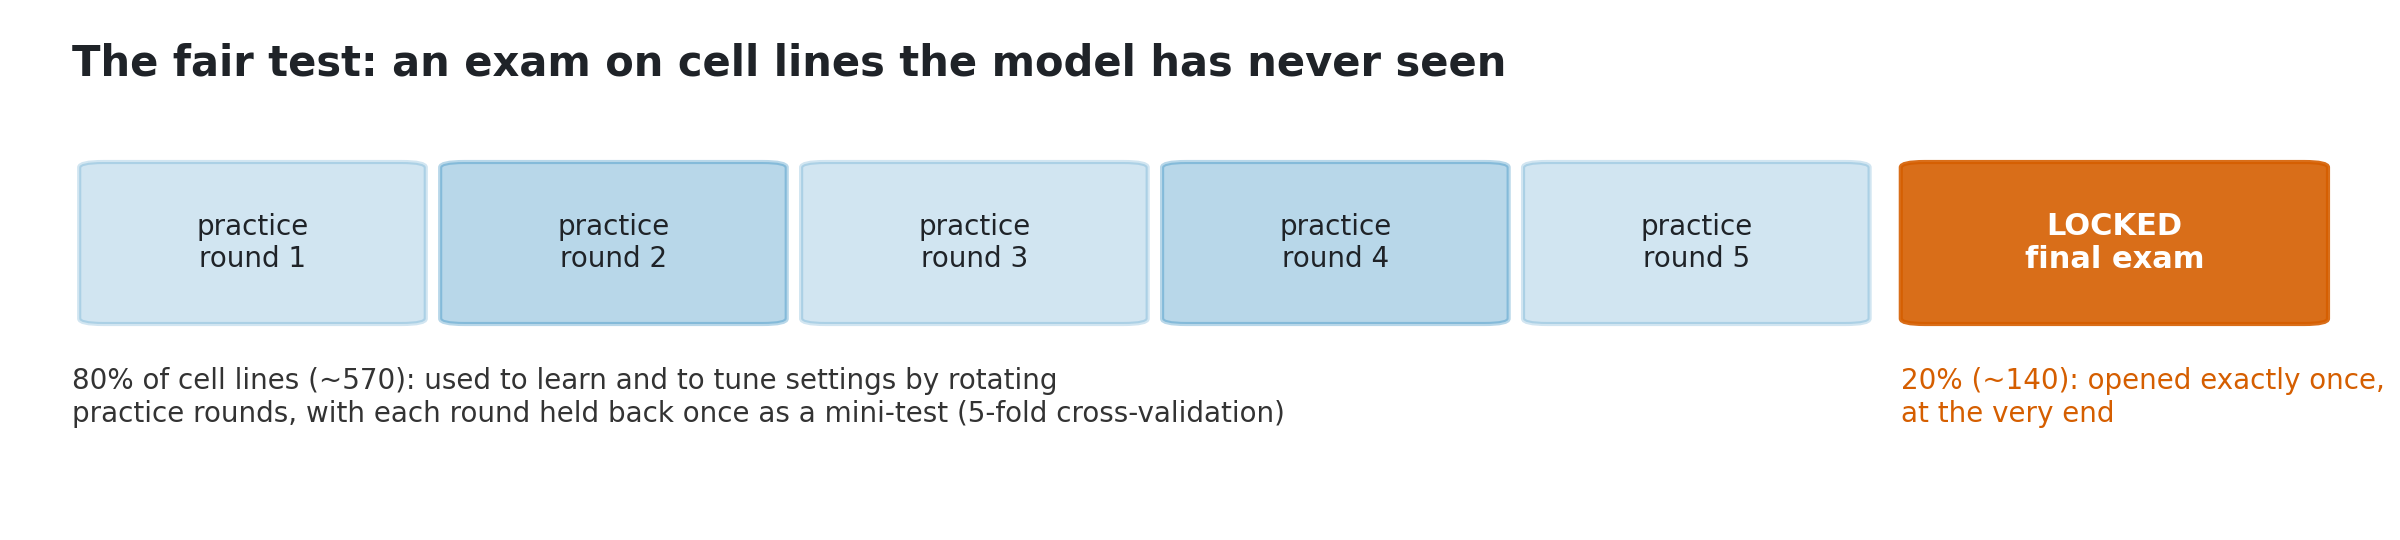

In [11]:
display(Image("images/fair_test.png", width=1000))

Two more safeguards:

- **The same locked cell lines are used for all 8 drugs**, so results are comparable across drugs.
- **The locked set is balanced by organ**, so it holds the same mix of lung, skin, blood and other cancers as the training set. A lucky or unlucky draw can't make one drug look easier.

<details>
<summary><b>For the technical reader</b>: split design and leakage controls</summary>

- **Split:** `train_test_split(test_size=0.2, stratify=tissue, random_state=42)` over cell lines. Each drug has its own model with one row per cell line, so this is a cell-line-disjoint split by construction.
- **Why 80/20:** it leaves ~140 test lines per drug. At that n, r ≈ 0.17 is significant at p < 0.05, so meaningful effects are resolvable.
- **Leakage controls:**
  - Variance-based gene selection, scaling and one-hot encoding live inside a scikit-learn `Pipeline`, so they are refit on every training fold.
  - The carrier threshold and the tissue grouping are computed on training lines only.
  - Hyperparameters are tuned with 5-fold CV inside the training set.
  - The test set is scored once.
- *Alternative considered:* one pooled model across all drugs. *Why not:* it needs a group-aware split, since each cell line appears once per drug, and its pooled metrics are inflated by between-drug potency differences. Per-drug models keep the question clinical ("for *this* drug, which tumours respond?").
</details>

In [12]:
TEST_SIZE = 0.2
MIN_CARRIERS = 10
MIN_TISSUE_LINES = 15
N_TOP_GENES = 2000

all_lines = pd.Index(sorted(response["ModelID"].unique()))
tissue_raw = lineage.reindex(all_lines).fillna("Unknown")
tissue_counts = tissue_raw.value_counts()
strata = tissue_raw.where(tissue_raw.map(tissue_counts) >= 2, "Other")    # stratifying needs >= 2 lines per group
train_lines, test_lines = train_test_split(all_lines, test_size=TEST_SIZE, stratify=strata, random_state=SEED)
train_lines, test_lines = pd.Index(train_lines), pd.Index(test_lines)

# Gene faults with enough carriers - counted on TRAINING lines only
carriers = mutated.loc[train_lines].sum()
mut_genes = sorted(carriers.index[carriers >= MIN_CARRIERS])
# Organ groups - defined on TRAINING lines only
train_tissue_counts = tissue_raw[train_lines].value_counts()
common_tissues = set(train_tissue_counts.index[train_tissue_counts >= MIN_TISSUE_LINES])
tissue = tissue_raw.where(tissue_raw.isin(common_tissues), "Other")

# One feature table for all cell lines (gene selection and scaling happen later, inside the pipeline)
features = pd.concat([expression.loc[all_lines].add_prefix("expr_"),
                      mutated.loc[all_lines, mut_genes].add_prefix("mut_").astype("float32"),
                      tissue.rename("tissue")], axis=1)
EXPR_COLS = [c for c in features if c.startswith("expr_")]
MUT_COLS = [c for c in features if c.startswith("mut_")]

print(f"Cell lines: {len(train_lines)} for learning  |  {len(test_lines)} locked away for the final test")
print(f"Inputs per cell line: {N_TOP_GENES:,} most variable of {len(EXPR_COLS):,} genes (chosen inside each practice round), "
      f"{len(MUT_COLS)} gene-fault flags, {len(common_tissues) + 1} organ groups")

Cell lines: 572 for learning  |  143 locked away for the final test
Inputs per cell line: 2,000 most variable of 19,215 genes (chosen inside each practice round), 58 gene-fault flags, 14 organ groups


## Step 6 · Modelling and hyperparameter tuning

For each drug, four "predictors" compete. Two are deliberately **lazy guesses** that set the bar; two are real models.

| Predictor | How it guesses a cell line's response | Role |
|---|---|---|
| **Average guess** | The same number for every cell line: the training average | The floor |
| **Organ-only guess** | The average of training cell lines from the same organ | **The real bar to beat.** Do genes add anything beyond the organ? |
| **Ridge regression** | A weighted sum of all the inputs, like a straight-line fit in Excel but with thousands of inputs | Simple, transparent model |
| **LightGBM** | Hundreds of small flowcharts of yes/no questions ("Is *BRAF* mutated? Is *BCL2* high?"), each one correcting the errors of the previous ones | Captures on/off effects and combinations |

> **In plain English:** with 2,000 inputs and only ~570 examples, a model can easily "memorise" the training data, like fitting a 50th-degree polynomial through 60 data points. Both models therefore have built-in **restraint**. Ridge penalises large weights, and LightGBM uses small, shallow trees. How much restraint to use is chosen in the practice rounds (5-fold cross-validation), never on the locked test set.

<details>
<summary><b>For the technical reader</b>: model choice and tuning grids</summary>

- **Ridge vs lasso or elastic net:** with thousands of correlated genes, lasso's selected set is unstable across folds. Ridge's L2 shrinkage is stable, and it is the classic strong baseline for this problem.
- **LightGBM vs random forest:** boosting is usually equal or better on tabular data. Trees capture step-like mutation effects that a linear model can only approximate.
- **Deep learning:** rejected. ~570 samples per drug is far too few for a neural network to beat regularised models.
- **Tuning:** 5-fold CV (`CV_FOLDS = 5`) on training lines, selecting on RMSE.
  - **Ridge:** `alpha` ∈ 10¹–10⁵ (9 log-spaced values). With 2,000+ standardized features and n ≈ 570, strong shrinkage is expected, so the grid is centred high.
  - **LightGBM, tuned:** trees {200, 500}, leaves per tree {7, 15}, minimum samples per leaf {10, 30}. These are deliberately small trees for small n.
  - **LightGBM, fixed:** learning rate 0.05, 80% row and 30% column subsampling. These are standard regularising defaults, and fixing them keeps the search to 8 combinations per drug.
- **Baselines:** the tissue-mean baseline is fitted on training lines, falling back to the global training mean for an unseen tissue.
</details>

In [13]:
CV_FOLDS = 5
RIDGE_ALPHAS = np.logspace(1, 5, 9)
LGBM_GRID = {"model__n_estimators": [200, 500], "model__num_leaves": [7, 15], "model__min_child_samples": [10, 30]}
LGBM_FIXED = dict(learning_rate=0.05, subsample=0.8, subsample_freq=1, colsample_bytree=0.3,
                  random_state=SEED, n_jobs=-1, verbose=-1)


def variance_score(X, y=None):
    '''Score each gene by how much its activity varies. It ignores y (the answer), so it cannot leak it.'''
    return np.var(X, axis=0)


def make_preprocessor(n_top_genes=N_TOP_GENES):
    '''Top-variance genes (standardized) + standardized gene-fault flags + one-hot organ.'''
    return ColumnTransformer([
        ("expr", Pipeline([("top_var", SelectKBest(variance_score, k=n_top_genes)), ("scale", StandardScaler())]), EXPR_COLS),
        ("mut", StandardScaler(), MUT_COLS),
        ("tissue", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["tissue"])])


def drug_data(drug):
    '''Training and locked-test inputs (X) and answers (y = ln IC50) for one drug.'''
    d = response[response["drug"] == drug].set_index("ModelID")["LN_IC50"]
    tr, te = d.index.intersection(train_lines), d.index.intersection(test_lines)
    return features.loc[tr], d[tr].values, features.loc[te], d[te].values


cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
fitted, preds, tuning = {}, {}, []
t0 = time.time()
for drug in DRUGS.values():
    X_tr, y_tr, X_te, y_te = drug_data(drug)
    p = {"y": y_te, "Average guess": np.full(len(y_te), y_tr.mean())}
    organ_means = pd.Series(y_tr, index=X_tr.index).groupby(X_tr["tissue"]).mean()
    p["Organ-only guess"] = X_te["tissue"].map(organ_means).fillna(y_tr.mean()).values

    ridge = GridSearchCV(Pipeline([("prep", make_preprocessor()), ("model", Ridge())]),
                         {"model__alpha": RIDGE_ALPHAS}, cv=cv, scoring="neg_root_mean_squared_error")
    lgbm = GridSearchCV(Pipeline([("prep", make_preprocessor()), ("model", lgb.LGBMRegressor(**LGBM_FIXED))]),
                        LGBM_GRID, cv=cv, scoring="neg_root_mean_squared_error")
    for name, search in [("Ridge", ridge), ("LightGBM", lgbm)]:
        search.fit(X_tr, y_tr)                       # learning + tuning use training lines only
        fitted[(drug, name)] = search.best_estimator_
        p[name] = search.predict(X_te)               # the locked test set is used here, once
        tuning.append({"drug": drug, "model": name, "CV RMSE (train folds)": -search.best_score_,
                       "best settings": {k.replace("model__", ""): v for k, v in search.best_params_.items()}})
    preds[drug] = p
    print(f"{drug:12s} trained on {len(y_tr)} lines, tested on {len(y_te)} locked lines  [{time.time() - t0:.0f}s]")
tuning = pd.DataFrame(tuning)

Dabrafenib   trained on 564 lines, tested on 141 locked lines  [304s]


Trametinib   trained on 572 lines, tested on 142 locked lines  [556s]


Erlotinib    trained on 566 lines, tested on 138 locked lines  [810s]


Alpelisib    trained on 571 lines, tested on 142 locked lines  [1065s]


Nutlin-3a    trained on 572 lines, tested on 143 locked lines  [1322s]


Venetoclax   trained on 569 lines, tested on 138 locked lines  [1578s]


Palbociclib  trained on 572 lines, tested on 143 locked lines  [1832s]


Paclitaxel   trained on 569 lines, tested on 138 locked lines  [2089s]


### 6.1 Robustness check: does the "2,000 genes" choice matter?

> **In plain English:** a good engineer checks that a result doesn't hinge on one arbitrary setting. We re-run the ridge model keeping 500, 2,000 or 5,000 genes and compare the error, **using the practice rounds only**. The locked test set stays locked.

In [14]:
GENE_COUNTS_TO_CHECK = [500, 2000, 5000]
sens = {}
for drug in DRUGS.values():
    X_tr, y_tr, _, _ = drug_data(drug)
    alpha = fitted[(drug, "Ridge")].named_steps["model"].alpha
    for k in GENE_COUNTS_TO_CHECK:
        pipe = Pipeline([("prep", make_preprocessor(k)), ("model", Ridge(alpha=alpha))])
        cv_pred = np.zeros(len(y_tr))
        for tr_i, va_i in cv.split(X_tr):
            cv_pred[va_i] = pipe.fit(X_tr.iloc[tr_i], y_tr[tr_i]).predict(X_tr.iloc[va_i])
        sens.setdefault(drug, {})[f"{k:,} genes"] = np.sqrt(mean_squared_error(y_tr, cv_pred))
sens = pd.DataFrame(sens).T
print("Typical prediction error in the practice rounds (RMSE, ln IC50 units; lower is better):")
sens.style.format("{:.3f}").highlight_min(axis=1, color="#D4EDDA")

Typical prediction error in the practice rounds (RMSE, ln IC50 units; lower is better):


,500 genes,"2,000 genes","5,000 genes"
Dabrafenib,1.415,1.406,1.430
Trametinib,1.782,1.665,1.656
Erlotinib,1.269,1.256,1.255
Alpelisib,1.201,1.191,1.207
Nutlin-3a,1.228,1.229,1.213
Venetoclax,1.343,1.289,1.283
Palbociclib,1.184,1.146,1.144
Paclitaxel,1.490,1.446,1.446


> **What this shows:** 2,000 and 5,000 genes give almost identical error for every drug (differences ≤ 0.03). 500 genes is noticeably worse for trametinib and venetoclax. So **2,000 is enough**, and the results don't hinge on this choice.

## Step 7 · Evaluation: the final exam

We now open the locked cell lines and score every predictor on them. Two scores are used, plus error bars:

| Score | What it measures | Engineering analogy |
|---|---|---|
| **Correlation (r)** | Does the model put the cell lines **in the right order**, from most to least sensitive? 1 = perfect order, 0 = random. | How well a sensor's reading tracks the true value |
| **Typical error (RMSE)** | How far off each prediction is, on average, in ln IC50 units. 1.0 ≈ off by a factor of 2.7 in dose. | ± tolerance |
| **95% error bars** | How much the score would wobble with a different set of ~140 test lines, found by re-drawing the test set 1,000 times (**bootstrapping**) | Measurement uncertainty |

**The key comparison** is each model against the **organ-only guess**. If the error bars on "improvement over organ-only" stay above zero, the genes are genuinely adding information.

<details>
<summary><b>For the technical reader</b>: metrics</summary>

- **Scoring set:** Pearson r and RMSE on the held-out lines; percentile-bootstrap 95% CIs (`N_BOOTSTRAP = 1000` resamples of test lines).
- **"Genomics beats tissue":** a paired bootstrap of the RMSE difference (organ-only minus best model), where "best model" is the lower-RMSE of Ridge and LightGBM on the test set. The claim holds if the 95% CI excludes 0.
- **Why not R²:** it conflates ranking with calibration and is easy to misread near zero. r and RMSE separate the two.
- **Why per-drug r at all:** a pooled r across drugs would be inflated by the fact that drugs simply differ in potency.
</details>

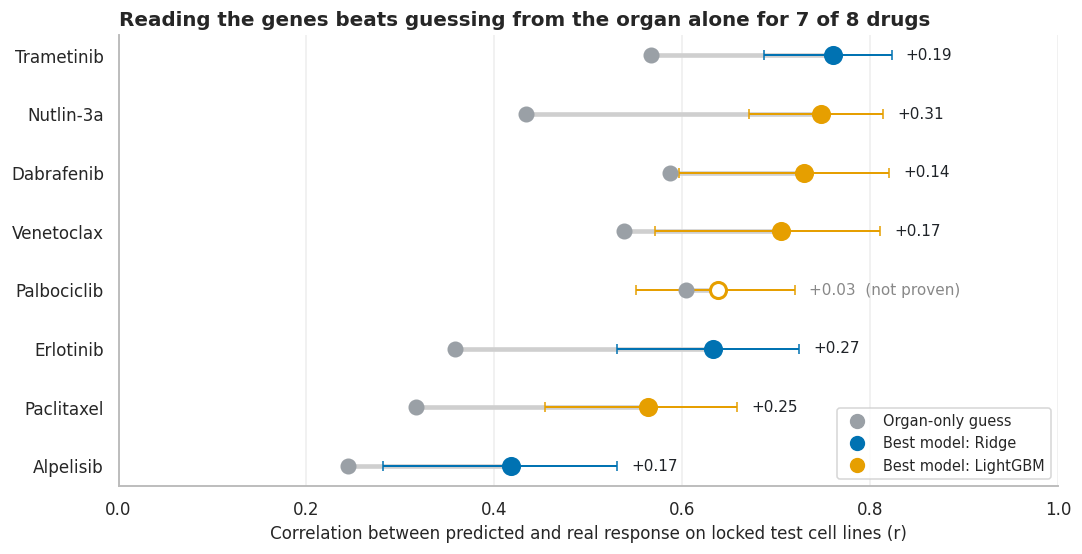

In [15]:
N_BOOTSTRAP = 1000
MODELS = ["Average guess", "Organ-only guess", "Ridge", "LightGBM"]
rng = np.random.default_rng(SEED)
rmse = lambda y, yhat: float(np.sqrt(mean_squared_error(y, yhat)))


def pearson_ci(y, yhat, n_boot=N_BOOTSTRAP):
    '''Pearson r and its 95% bootstrap interval (resampling test cell lines). NaN for constant predictions.'''
    if np.ptp(yhat) < 1e-9:
        return np.nan, np.nan, np.nan
    idx = rng.integers(0, len(y), size=(n_boot, len(y)))
    boots = [stats.pearsonr(y[i], yhat[i])[0] for i in idx if np.ptp(yhat[i]) > 1e-9]
    return stats.pearsonr(y, yhat)[0], *np.percentile(boots, [2.5, 97.5])


rows, gain_rows = [], []
for drug, p in preds.items():
    for m in MODELS:
        r, lo, hi = pearson_ci(p["y"], p[m])
        rows.append({"drug": drug, "model": m, "r": r, "r_lo": lo, "r_hi": hi, "RMSE": rmse(p["y"], p[m])})
    best = min(["Ridge", "LightGBM"], key=lambda m: rmse(p["y"], p[m]))
    idx = rng.integers(0, len(p["y"]), size=(N_BOOTSTRAP, len(p["y"])))
    diffs = [rmse(p["y"][i], p["Organ-only guess"][i]) - rmse(p["y"][i], p[best][i]) for i in idx]
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    gain_rows.append({"drug": drug, "best model": best,
                      "error reduction vs organ-only (RMSE)": rmse(p["y"], p["Organ-only guess"]) - rmse(p["y"], p[best]),
                      "95% interval": f"[{lo:.2f}, {hi:.2f}]", "genes add real value?": "Yes" if lo > 0 else "Not proven",
                      "_significant": lo > 0})
results = pd.DataFrame(rows)
gain = pd.DataFrame(gain_rows).set_index("drug")

# ---- Headline figure: organ-only guess -> best gene-based model --------------------------------
org = results[results["model"] == "Organ-only guess"].set_index("drug")
best_rows = pd.DataFrame([results[(results["drug"] == d) & (results["model"] == gain.loc[d, "best model"])].iloc[0]
                          for d in DRUGS.values()]).set_index("drug")
order = best_rows["r"].sort_values().index
fig, ax = plt.subplots(figsize=(10, 5.2))
for i, drug in enumerate(order):
    o, b = org.loc[drug, "r"], best_rows.loc[drug]
    sig = gain.loc[drug, "_significant"]
    col = BLUE if gain.loc[drug, "best model"] == "Ridge" else ORANGE
    ax.plot([o, b["r"]], [i, i], color="#CFCFCF", lw=3, zorder=1)
    ax.scatter(o, i, s=90, color=GREY, zorder=3)
    ax.errorbar(b["r"], i, xerr=[[b["r"] - b["r_lo"]], [b["r_hi"] - b["r"]]], fmt="none", ecolor=col, elinewidth=1.3,
                capsize=3, zorder=2)
    ax.scatter(b["r"], i, s=110, color=col if sig else "white", edgecolor=col, linewidth=2, zorder=4)
    ax.text(b["r_hi"] + 0.015, i, f"+{b['r'] - o:.2f}" + ("" if sig else "  (not proven)"), va="center",
            fontsize=10, color=INK if sig else "#888")
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=11)
ax.set_xlim(0, 1.0); ax.set_xlabel("Correlation between predicted and real response on locked test cell lines (r)")
n_sig = int(gain["_significant"].sum())
ax.set_title(f"Reading the genes beats guessing from the organ alone for {n_sig} of {len(DRUGS)} drugs")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=GREY, ms=9, label="Organ-only guess"),
                   Line2D([], [], marker="o", ls="", color=BLUE, ms=9, label="Best model: Ridge"),
                   Line2D([], [], marker="o", ls="", color=ORANGE, ms=9, label="Best model: LightGBM")],
          loc="lower right", frameon=True, fontsize=9.5)
ax.grid(axis="y", visible=False)
plt.tight_layout(); save(fig, "results.png"); plt.show()

> **What this shows:** for **7 of 8 drugs**, reading the genes clearly beats guessing from the organ alone. The error bars on the improvement stay above zero. The biggest gains:
>
> | Drug | Organ-only r | Best model r |
> |---|:---:|:---:|
> | Nutlin-3a | 0.43 | **0.75** |
> | Trametinib | 0.57 | **0.76** |
> | Erlotinib | 0.36 | **0.63** |
>
> **Palbociclib is the exception** (hollow dot). The organ already explains most of what can be predicted (mainly that blood cancers respond), and the genes add too little to be sure of.

The full scoreboard, including the two individual models:

In [16]:
board = results.pivot(index="drug", columns="model", values="r").reindex(index=DRUGS.values(), columns=MODELS)
board.columns = [f"r · {c}" for c in board.columns]
err = results.pivot(index="drug", columns="model", values="RMSE").reindex(index=DRUGS.values(), columns=MODELS)
err.columns = [f"error · {c}" for c in err.columns]
scoreboard = pd.concat([board.drop(columns="r · Average guess"), err], axis=1)
BEST = "background-color: #D4EDDA; font-weight: bold"
display(scoreboard.style.format("{:.2f}", na_rep="–")
        .highlight_max(axis=1, subset=[c for c in scoreboard if c.startswith("r ·")], props=BEST)
        .highlight_min(axis=1, subset=[c for c in scoreboard if c.startswith("error ·")], props=BEST))
gain.drop(columns="_significant").style.format({"error reduction vs organ-only (RMSE)": "{:.2f}"})

,r · Organ-only guess,r · Ridge,r · LightGBM,error · Average guess,error · Organ-only guess,error · Ridge,error · LightGBM
drug,,,,,,,
Dabrafenib,0.59,0.65,0.73,1.70,1.39,1.29,1.17
Trametinib,0.57,0.76,0.71,2.40,1.98,1.63,1.70
Erlotinib,0.36,0.63,0.62,1.25,1.17,0.98,0.98
Alpelisib,0.24,0.42,0.39,1.46,1.43,1.33,1.34
Nutlin-3a,0.43,0.66,0.75,1.78,1.62,1.33,1.19
Venetoclax,0.54,0.65,0.70,1.98,1.67,1.51,1.41
Palbociclib,0.60,0.64,0.64,1.46,1.17,1.15,1.13
Paclitaxel,0.32,0.57,0.56,1.74,1.68,1.44,1.44


,best model,error reduction vs organ-only (RMSE),95% interval,genes add real value?
drug,,,,
Dabrafenib,LightGBM,0.22,"[0.07, 0.37]",Yes
Trametinib,Ridge,0.35,"[0.20, 0.51]",Yes
Erlotinib,Ridge,0.19,"[0.11, 0.27]",Yes
Alpelisib,Ridge,0.10,"[0.03, 0.17]",Yes
Nutlin-3a,LightGBM,0.43,"[0.29, 0.57]",Yes
Venetoclax,LightGBM,0.27,"[0.09, 0.46]",Yes
Palbociclib,LightGBM,0.04,"[-0.05, 0.14]",Not proven
Paclitaxel,LightGBM,0.24,"[0.12, 0.35]",Yes


> **What this shows:** *(the best score in each row is highlighted green: highest r, lowest error)*
>
> - **Neither model wins everywhere, and that pattern makes sense:**
>   - **LightGBM (flowcharts) wins** when one strong on/off switch dominates, such as *BRAF* for dabrafenib, *TP53* for Nutlin-3a, or *BCL2* for venetoclax. Yes/no questions capture on/off effects naturally.
>   - **Ridge (weighted sum) is as good or better** when the signal is spread thinly over many genes, as for trametinib, erlotinib and alpelisib.
> - **The average guess has no correlation by design**, because it predicts the same number for everyone. It is included only to show how large the error is when you know nothing: about 1.2 to 2.4 units.
> - **Differences of a few hundredths between models are within the error bars** and shouldn't be over-read.

### 7.1 What does a correlation of 0.7 actually look like?

Each dot below is one **locked test** cell line: the model's prediction against the real lab result. Dots on the diagonal would be perfect predictions. Colour shows the known biomarker.

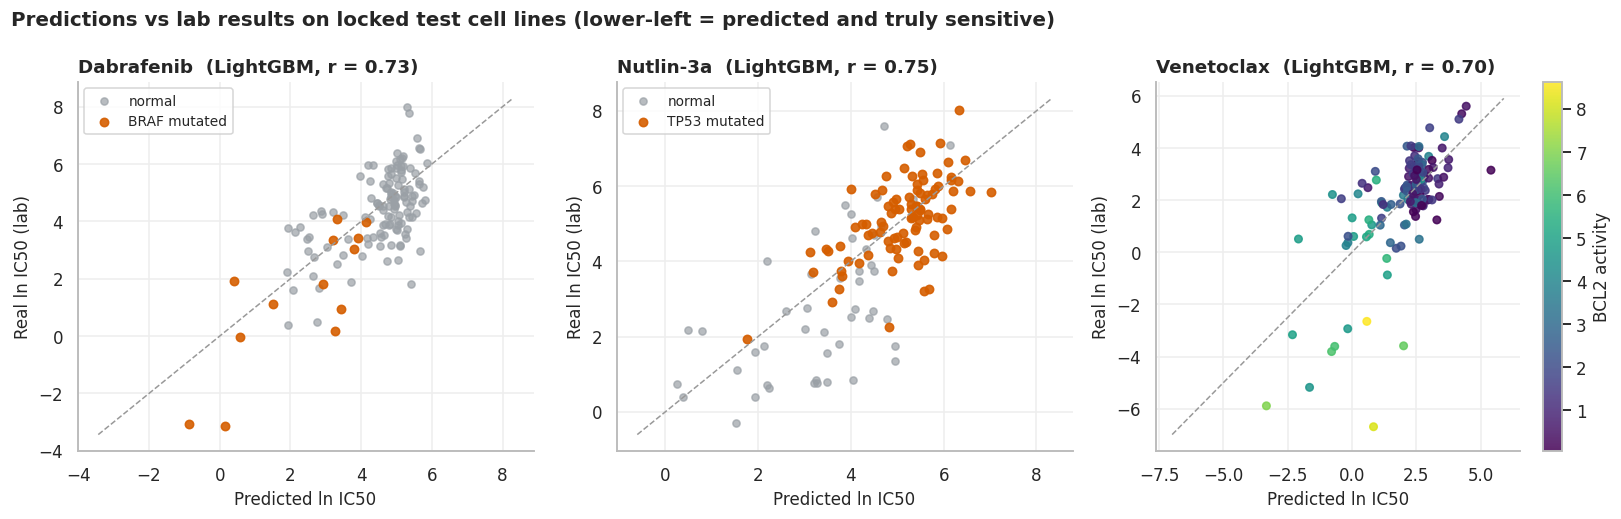

In [17]:
examples = [("Dabrafenib", "BRAF"), ("Nutlin-3a", "TP53"), ("Venetoclax", "BCL2")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (drug, gene) in zip(axes, examples):
    best = gain.loc[drug, "best model"]
    _, _, X_te, y_te = drug_data(drug)
    yhat = preds[drug][best]
    if BIOMARKERS[drug][0] == "mut":
        is_mut = mutated.loc[X_te.index, gene].values == 1
        ax.scatter(yhat[~is_mut], y_te[~is_mut], s=22, color=GREY, alpha=0.7, label="normal")
        ax.scatter(yhat[is_mut], y_te[is_mut], s=30, color=VERMILION, alpha=0.9, label=f"{gene} mutated")
        ax.legend(loc="upper left", fontsize=9, frameon=True)
    else:
        sc = ax.scatter(yhat, y_te, s=24, c=expression.loc[X_te.index, gene].values, cmap="viridis", alpha=0.85)
        plt.colorbar(sc, ax=ax, label=f"{gene} activity")
    lims = [min(yhat.min(), y_te.min()) - 0.3, max(yhat.max(), y_te.max()) + 0.3]
    ax.plot(lims, lims, color="#999", ls="--", lw=1)
    r = stats.pearsonr(y_te, yhat)[0]
    ax.set_title(f"{drug}  ({best}, r = {r:.2f})", fontsize=12)
    ax.set_xlabel("Predicted ln IC50"); ax.set_ylabel("Real ln IC50 (lab)")
fig.suptitle("Predictions vs lab results on locked test cell lines (lower-left = predicted and truly sensitive)",
             x=0.01, ha="left", fontsize=13, weight="bold")
plt.tight_layout(); save(fig, "predicted_vs_actual.png"); plt.show()

> **What this shows:** the models push the biomarker-positive cell lines (orange dots, or green-yellow for high *BCL2* activity) toward the correct end.
>
> - For dabrafenib, most of the truly sensitive lines (bottom of the chart) are *BRAF*-mutant, and the model gives the most extreme of them its lowest predictions.
> - For Nutlin-3a, it's the opposite: the *TP53*-mutant lines are predicted **resistant**, correctly.
>
> A correlation of ~0.7 isn't a perfect crystal ball, but it **separates responders from non-responders** well.

### 7.2 Sensitive or not? And a memorisation check

Doctors think in categories (will it work, yes or no?), so we also measure how well each model separates **sensitive** cell lines from the rest. "Sensitive" means the drug killed half the cells *within the doses the lab actually tested*. We score this with **AUC**: 0.5 is a coin flip, 1.0 is a perfect separation.

We also compare each model's error in the **practice rounds** with its error on the **locked test**. If a model had memorised its training data, it would do much worse on the test.

<details>
<summary><b>For the technical reader</b></summary>

- **Label:** sensitive ⇔ ln IC50 < ln(`MAX_CONC`), a drug-specific, pharmacologically anchored cutoff. `MAX_CONC` is each cell line's *own* highest tested dose: for 4 of the 8 drugs (erlotinib, alpelisib, palbociclib, paclitaxel), GDSC tested some lines up to a different top dose, so a single per-drug cutoff would mislabel them.
  - *Alternative considered:* a median split. *Why not:* it calls half of all lines "sensitive" even for a drug that barely works at tested doses.
- **Minimum class size:** AUC is reported only when the test set has ≥ `MIN_CLASS_COUNT = 5` lines in each class. Below that, one line moves the AUC by more than 0.2.
</details>

In [18]:
MIN_CLASS_COUNT = 5
auc_rows = []
for drug, p in preds.items():
    _, _, X_te, _ = drug_data(drug)
    # each cell line's OWN highest tested dose (GDSC tested some lines of 4 drugs at a different top dose)
    max_dose = response[response["drug"] == drug].set_index("ModelID")["MAX_CONC"].reindex(X_te.index).values
    sensitive = (p["y"] < np.log(max_dose)).astype(int)
    row = {"drug": drug, "sensitive lines in test": f"{sensitive.sum()} of {len(sensitive)}"}
    for m in ["Organ-only guess", "Ridge", "LightGBM"]:
        ok = min(sensitive.sum(), len(sensitive) - sensitive.sum()) >= MIN_CLASS_COUNT
        row[f"AUC · {m}"] = roc_auc_score(sensitive, -p[m]) if ok else np.nan
    auc_rows.append(row)
auc = pd.DataFrame(auc_rows).set_index("drug")
display(auc.style.format("{:.2f}", subset=[c for c in auc if c.startswith("AUC")])
        .background_gradient(cmap="Blues", subset=[c for c in auc if c.startswith("AUC")], vmin=0.5, vmax=1.0))

overfit = tuning.pivot(index="drug", columns="model", values="CV RMSE (train folds)").reindex(DRUGS.values())
check = pd.DataFrame({"Ridge · practice error": overfit["Ridge"],
                      "Ridge · test error": err["error · Ridge"],
                      "LightGBM · practice error": overfit["LightGBM"],
                      "LightGBM · test error": err["error · LightGBM"]})
check.style.format("{:.2f}")

,sensitive lines in test,AUC · Organ-only guess,AUC · Ridge,AUC · LightGBM
drug,,,,
Dabrafenib,16 of 141,0.85,0.88,0.91
Trametinib,58 of 142,0.79,0.91,0.87
Erlotinib,14 of 138,0.64,0.85,0.81
Alpelisib,18 of 142,0.66,0.74,0.72
Nutlin-3a,24 of 143,0.66,0.83,0.92
Venetoclax,11 of 138,0.80,0.85,0.92
Palbociclib,30 of 143,0.85,0.86,0.87
Paclitaxel,53 of 138,0.56,0.66,0.67


,Ridge · practice error,Ridge · test error,LightGBM · practice error,LightGBM · test error
drug,,,,
Dabrafenib,1.38,1.29,1.36,1.17
Trametinib,1.66,1.63,1.67,1.70
Erlotinib,1.25,0.98,1.27,0.98
Alpelisib,1.19,1.33,1.16,1.34
Nutlin-3a,1.23,1.33,1.14,1.19
Venetoclax,1.28,1.51,1.24,1.41
Palbociclib,1.15,1.15,1.18,1.13
Paclitaxel,1.44,1.44,1.48,1.44


> **What this shows:**
>
> - **Sensitive vs not:** the best gene-based model reaches **AUC 0.67–0.92**, against 0.56–0.85 for the organ-only guess, and is higher for every drug (by only 0.02 for palbociclib). Nutlin-3a jumps from 0.66 to 0.92.
> - **Paclitaxel is the weakest here (AUC 0.67).** It ranks cell lines reasonably well (r = 0.56), but cleanly separating the ~40% of lines that respond within the tested doses from the rest is harder.
> - **Sensitive lines are few for some drugs** (11 to 58 per drug in the test set), so these AUCs carry real uncertainty. Venetoclax's rests on only 11 sensitive lines.
> - **No sign of memorisation:** practice and test errors are within about 0.1 for most drugs, and where they differ, they differ **in both directions**. Venetoclax's test error is higher than in practice; erlotinib's is *lower*. That pattern reflects which ~140 lines happened to land in the test set, not memorisation. Repeating the split with different seeds would narrow this down (see Next steps).

## Step 8 · Interpretation: checking the model's reasoning

A good score isn't enough. A model can score well for the wrong reasons, like a student who passes by spotting patterns in how the questions are worded. So we open up each model and ask **which inputs it relied on**, using a method called **SHAP**.

> **In plain English:** SHAP splits each prediction into contributions from each input. It works the way an engineer breaks a beam's total deflection into the contribution of each load (superposition). For each drug, we then check two things:
>
> 1. **Where does the answer-key gene rank** among the ~2,070 inputs?
> 2. **Does it push in the right direction?** For example, a *BRAF* mutation should push the prediction toward *sensitive* for dabrafenib.
>
> If the model rediscovers the textbook gene **without being told**, that is strong evidence it learned real biology.

<details>
<summary><b>For the technical reader</b>: SHAP implementation</summary>

- **Computation:** SHAP values come from LightGBM's exact TreeSHAP (`pred_contrib=True`) on the locked test lines, and are plotted with the `shap` library.
- **Ranking:** by mean |SHAP| across test lines.
- **Direction:** the sign of the Spearman correlation between a feature's value and its SHAP value. A feature the trees never split on is reported as "not used".
- **Second opinion:** ridge's coefficient sign.
- **Verdict rule:** "Yes" requires the right direction *and* a rank in the top `TOP_RANK = 20` inputs (top 1% of ~2,070). The right direction at a lower rank is reported as "minor role".
- *Alternative considered:* LightGBM's built-in split-count importance. *Why not:* it has no direction and is biased toward continuous features.
</details>

In [19]:
def pretty(name):
    '''Readable input names: expr__expr_BCL2 -> "BCL2 (activity)", mut__mut_BRAF -> "BRAF (mutated)".'''
    part, feat = name.split("__", 1)
    if part == "expr":
        return feat.replace("expr_", "") + " (activity)"
    if part == "mut":
        return feat.replace("mut_", "") + " (mutated)"
    return "organ: " + feat.replace("tissue_", "")


TOP_RANK = 20   # "a top input" = within the top 20 of ~2,070 inputs (top 1%)
shap_store, check_rows = {}, []
for drug, (kind, gene, expected) in BIOMARKERS.items():
    pipe = fitted[(drug, "LightGBM")]
    _, _, X_te, _ = drug_data(drug)
    Xt = pipe.named_steps["prep"].transform(X_te)
    names = [pretty(n) for n in pipe.named_steps["prep"].get_feature_names_out()]
    contrib = pipe.named_steps["model"].predict(Xt, pred_contrib=True)
    shap_store[drug] = shap.Explanation(values=contrib[:, :-1], base_values=contrib[:, -1], data=Xt, feature_names=names)
    importance = pd.Series(np.abs(contrib[:, :-1]).mean(0), index=names).sort_values(ascending=False)
    feat = f"{gene} ({'mutated' if kind == 'mut' else 'activity'})"
    row = {"drug": drug, "answer-key input": feat,
           "expected effect": {"lower": "→ more sensitive", "higher": "→ more resistant"}.get(expected, "none (control)"),
           "top 3 inputs the model relied on": ", ".join(importance.index[:3])}
    j = names.index(feat)
    ridge = fitted[(drug, "Ridge")]
    r_names = [pretty(n) for n in ridge.named_steps["prep"].get_feature_names_out()]
    coef = ridge.named_steps["model"].coef_[r_names.index(feat)]
    if np.abs(contrib[:, j]).max() == 0:            # the trees never used this input
        lgbm_dir = "not used"
    else:                                           # > 0 means higher value -> higher predicted ln IC50 (more resistant)
        lgbm_dir = "higher" if stats.spearmanr(Xt[:, j], contrib[:, j])[0] > 0 else "lower"
    ridge_dir = "higher" if coef > 0 else "lower"
    rank = list(importance.index).index(feat) + 1
    if expected == "none expected":
        verdict = "n/a (control)"
    elif lgbm_dir == expected and rank <= TOP_RANK:
        verdict = "Yes"
    elif lgbm_dir == expected:
        verdict = "Right direction, minor role"
    elif lgbm_dir == "not used":
        verdict = "Only the ridge model" if ridge_dir == expected else "No"
    else:
        verdict = "No"
    row.update({"rank among all inputs": f"{rank:,} of {len(names):,}",
                "matches textbook biology?": verdict})
    check_rows.append(row)
biology_check = pd.DataFrame(check_rows).set_index("drug")
biology_check

,answer-key input,expected effect,top 3 inputs the model relied on,rank among all inputs,matches textbook biology?
drug,,,,,
Dabrafenib,BRAF (mutated),→ more sensitive,"BRAF (mutated), IL16 (activity), WNT7B (activity)","1 of 2,072",Yes
Trametinib,BRAF (mutated),→ more sensitive,"ETV4 (activity), FOSL1 (activity), FCGR2A (activity)","15 of 2,072",Yes
Erlotinib,EGFR (mutated),→ more sensitive,"organ: Pancreas, TM4SF18 (activity), DUSP6 (activity)","520 of 2,072","Right direction, minor role"
Alpelisib,PIK3CA (mutated),→ more sensitive,"MET (activity), PIK3CA (mutated), S100A6 (activity)","2 of 2,072",Yes
Nutlin-3a,TP53 (mutated),→ more resistant,"TP53 (mutated), CDKN2A (activity), CYFIP2 (activity)","1 of 2,072",Yes
Venetoclax,BCL2 (activity),→ more sensitive,"BCL2 (activity), YAP1 (activity), TNFRSF12A (activity)","1 of 2,072",Yes
Palbociclib,RB1 (mutated),→ more resistant,"SDC4 (activity), LURAP1L (activity), PXDC1 (activity)","1,771 of 2,072",Only the ridge model
Paclitaxel,TP53 (mutated),none (control),"SEPTIN6 (activity), ABCB1 (activity), IL13RA1 (activity)","979 of 2,072",n/a (control)


> **What this shows: the models learned real biology.**
>
> -  **The textbook gene is the #1 input** for dabrafenib (*BRAF*), Nutlin-3a (*TP53*) and venetoclax (*BCL2*), and #2 for alpelisib (*PIK3CA*). In every case it pushes in the textbook direction. Out of ~2,070 inputs, the model found them unaided.
> -  **Trametinib: a smarter route to the same answer.** *BRAF* ranks 15th, but the top two inputs are ***ETV4*** and ***FOSL1*** activity. These genes are switched on *by* the overactive signalling pathway that trametinib blocks. In car terms, *BRAF* is the stuck accelerator pedal, and *ETV4*/*FOSL1* are the speedometer reading "very fast". The speedometer catches every way the engine can be racing, not just the one stuck pedal. Researchers reported exactly this in 2010 (Dry et al., *Cancer Research*).
> -  **Erlotinib: too rare to learn.** Its key gene points the right way but ranks only 520th. With only ~15 mutated examples in training, the model can't learn the rule, so it leans on the organ of origin and other clues instead. This is a genuine limitation of learning from data, and it shows up clearly here.
> -  **Palbociclib:** the flowchart model never used *RB1*. The ridge model gives it the right direction, but a tiny weight. This fits Step 7, where the organ explained most of palbociclib's response.

Below are the top 10 inputs for four drugs. Each dot is one test cell line. **Left of centre = pushed toward "drug works"**. Colour = the input's value (red = high or mutated, blue = low or normal).

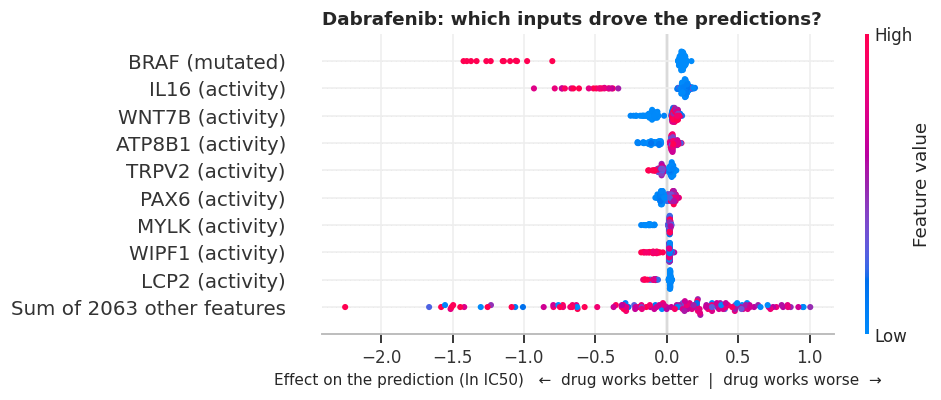

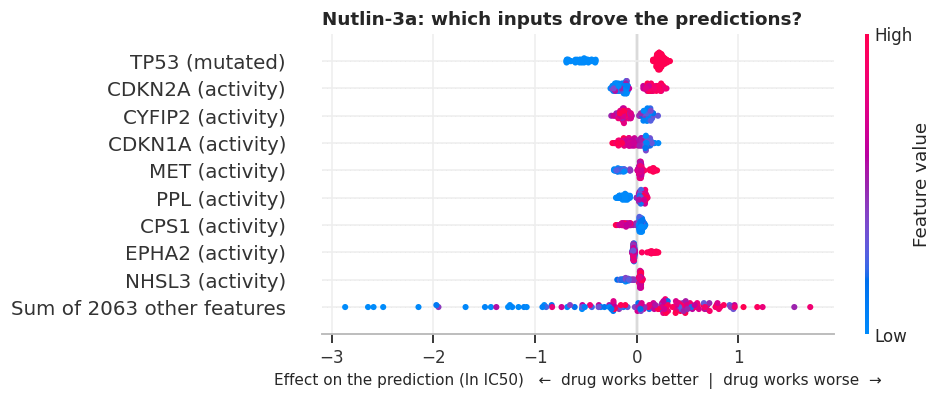

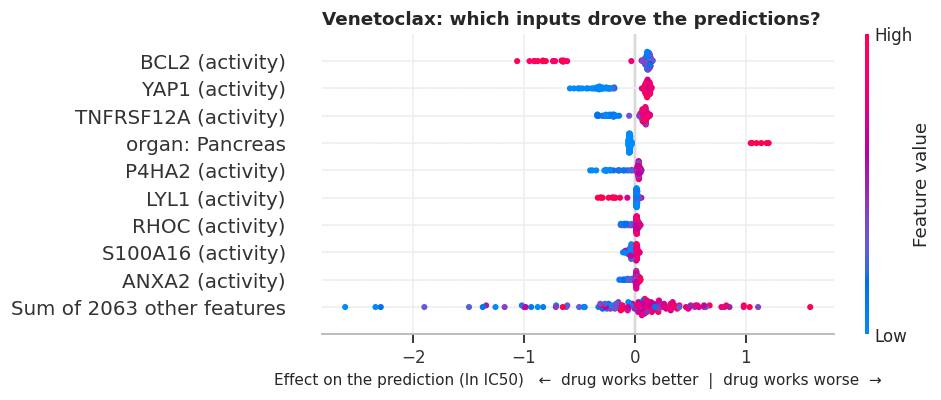

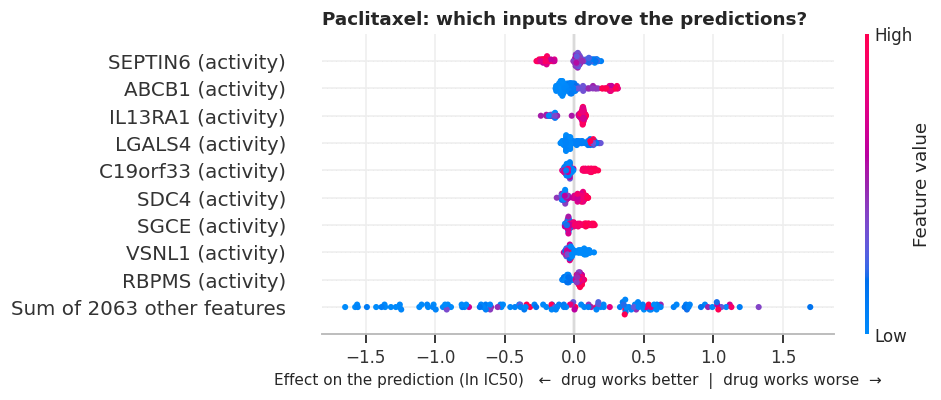

In [20]:
SHAP_EXAMPLES = ["Dabrafenib", "Nutlin-3a", "Venetoclax", "Paclitaxel"]
for drug in SHAP_EXAMPLES:
    plt.figure()
    shap.plots.beeswarm(shap_store[drug], max_display=10, show=False, plot_size=(9, 3.8))
    fig = plt.gcf()
    plt.title(f"{drug}: which inputs drove the predictions?", fontsize=12, loc="left")
    plt.xlabel("Effect on the prediction (ln IC50)   ←  drug works better  |  drug works worse  →", fontsize=10)
    plt.tight_layout()
    if drug == "Paclitaxel":
        save(fig, "shap_paclitaxel.png")
    plt.show()

> **What this shows:**
>
> - **Dabrafenib:** *BRAF*-mutated lines (red) sit far to the left. The model has learned "BRAF fault → drug works".
> - **Nutlin-3a:** *TP53*-mutated lines are pushed right, toward resistance, exactly as the biology predicts. The model also uses *CDKN1A*, a gene that a *working* TP53 switches on. That is a second, independent sign it has picked up the TP53 mechanism.
> - **Venetoclax:** high *BCL2* activity pushes toward "drug works".
> - **Paclitaxel, the control with no known rule:** among the top inputs is ***ABCB1***. High activity (red) pushes toward "drug works *worse*". *ABCB1* makes a **pump that throws paclitaxel back out of the cell**, one of the best-known causes of chemotherapy resistance. The model rediscovered it from gene activity alone.

## Limitations: what this study does *not* show

1. **Cell lines are not patients.** They have no immune system, no blood supply and no surrounding tissue, and decades in the lab have changed them. Nothing here predicts a real patient's outcome.
2. **Lab response ≠ clinical response.** Killing half the cells in a dish at a given dose doesn't mean that dose can safely be reached in a person.
3. **The drugs were chosen *because* they have known rules.** That made them good answer keys, but it means these scores are an **upper end**. A randomly chosen drug would likely score lower.
4. **Rare gene faults can't be learned.** Erlotinib shows this: too few examples, too little to learn from.
5. **Many resistance values are estimates.** When a drug never killed half the cells within the tested doses, the IC50 was extrapolated (line C in Step 1). Modelling a different response measure (area under the curve), or capping extrapolated values, would be a useful robustness check.
6. **Lab measurements are noisy.** Independent labs testing the same drugs on the same cell lines agree only moderately (Haibe-Kains et al., *Nature* 2013), which caps how accurate any model can be.
7. **One split, one seed.** The error bars cover which cell lines landed in the test set, but not the variation from repeating the whole split several times.

## Next steps (deliberately out of scope)

- **All ~290 drugs.** Run the same pipeline on every GDSC drug to see which *kinds* of drugs are predictable.
- **Gene copy number.** Add extra copies of a gene as an input, e.g. *ERBB2* amplification for HER2 drugs.
- **Brand-new drugs.** Build one shared model across drugs and test it on drugs it has never seen.
- **Patient tumours.** Check whether the same signals point the same way in real tumours (e.g. The Cancer Genome Atlas).
- **Repeated splits.** Re-run with several random splits to measure stability.

## Conclusion

**Can a cancer's genes predict which drug will work?** For drugs whose effect depends on a specific genetic weakness: yes, clearly beyond what the organ of origin already tells you.

- **Genes beat the organ-only guess.** Across ~140 unseen cell lines, simple per-drug models ranked sensitivity with correlations of **0.42–0.76**, and beat the organ-only guess for **7 of 8 drugs**.
- **The models got there for the right reasons.** Unaided, they rediscovered *BRAF*, *TP53*, *BCL2* and *PIK3CA*, found the signalling "speedometer" genes behind trametinib, and found the *ABCB1* drug pump behind paclitaxel resistance.
- **The failures are informative too:**
  - a real but **rare** genetic rule (*EGFR* for erlotinib) can't be learned from ~700 cell lines;
  - for palbociclib, the **organ of origin** explains most of what's predictable.

For a drug developer or a health-economics team, that distinction is the useful output. It separates drugs where a genetic test could plausibly guide treatment from drugs where it would add little.

**In one sentence:** *a careful method with a genuinely unseen test set shows that reading the genes adds real predictive value for most of these drugs, and the models rediscover known biology unaided, which is evidence the method can be trusted on questions where the answer isn't yet known.*

## Decision log

Every significant choice in this project, what was chosen, and why.

| # | Decision | Choice | Because |
|---|---|---|---|
| 1 | Data | GDSC2 Release 8.5 + DepMap gene activity & mutations | The largest public drug screen, joined to the most complete cell-line genetics |
| 2 | Copy number | Left out | Its drug-relevant effects mostly show up in gene activity; keeps the inputs explainable |
| 3 | Joining | Shared Sanger ID code, not cell-line names | Names are formatted inconsistently and silently mismatch |
| 4 | Missing genetics | Drop the cell line, don't fill in | Filling in a whole genome would fabricate the input |
| 5 | Drugs | 7 drugs with known rules + 1 chemotherapy control | Gives an answer key to verify the models' reasoning |
| 6 | Response measure | ln IC50, extrapolated values kept | Log scale suits a 10,000-fold range; dropping extrapolations would remove the resistant lines |
| 7 | Model structure | One model per drug | Keeps the question clinical and stops differences in drug strength inflating scores |
| 8 | Fair test | 20% of cell lines locked away, balanced by organ, same for all drugs | The test must use unseen cell lines, with results comparable across drugs |
| 9 | Leakage control | Gene selection, scaling and tuning inside training folds only; test opened once | Anything tuned on test data inflates results |
| 10 | Gene activity inputs | 2,000 most variable genes (checked against 500 and 5,000) | Selection never sees the answer; results were stable across counts |
| 11 | Gene-fault inputs | ~100 known cancer genes, kept if ≥ 10 training carriers | Holds the known rules; rarer faults can't be learned |
| 12 | Baselines | Average guess + **organ-only guess** | Genes must beat what the organ already tells a doctor |
| 13 | Models | Ridge + LightGBM, tuned by 5-fold cross-validation | A strong linear and a strong non-linear model; too few samples for deep learning |
| 14 | Scores | Correlation + error with bootstrap error bars, plus AUC | Ranking, error size and uncertainty, plus a yes/no view doctors use |
| 15 | Reasoning check | SHAP compared against the answer key | A model that scores well for the wrong reasons can't be trusted |

## Reproduce this analysis

1. `pip install -r requirements.txt`
2. Download the five data files listed in Step 1 into `data/`.
3. Run all cells (~45 min on 2 cores; faster on a typical laptop). With the same data and seed, the numbers match exactly.

## References

- Iorio F. *et al.* (2016). A landscape of pharmacogenomic interactions in cancer. *Cell* 166:740–754. (GDSC)
- Yang W. *et al.* (2013). Genomics of Drug Sensitivity in Cancer (GDSC). *Nucleic Acids Research* 41:D955–D961.
- Tsherniak A. *et al.* (2017). Defining a cancer dependency map. *Cell* 170:564–576. (DepMap)
- Ghandi M. *et al.* (2019). Next-generation characterization of the Cancer Cell Line Encyclopedia. *Nature* 569:503–508.
- Dry J.R. *et al.* (2010). Transcriptional pathway signatures predict MEK addiction and response to selumetinib. *Cancer Research* 70:2264–2273.
- Haibe-Kains B. *et al.* (2013). Inconsistency in large pharmacogenomic studies. *Nature* 504:389–393.
- Lundberg S.M. & Lee S.-I. (2017). A unified approach to interpreting model predictions. *NeurIPS*. (SHAP)
- Ke G. *et al.* (2017). LightGBM: a highly efficient gradient boosting decision tree. *NeurIPS*.

## Appendix A · Section guide

What was done at each standard stage of the analysis, and where to find it.

| # | Stage | Section | What was done | Output |
|---|---|---|---|---|
| 1 | **Problem framing** | The problem · Key words | Framed the question: do a cancer's genes predict drug response *beyond* what its tissue of origin already tells you? Defined the key terms. | Research question; success criterion (beat the organ-only guess) |
| 2 | **Data acquisition** | Step 1 | Loaded GDSC2 Release 8.5 drug responses (242,036 results; 969 cell lines × 295 drugs) and the DepMap cell-line tables: metadata, gene activity for 19,215 genes, and two mutation tables. | Raw tables |
| 3 | **Data cleaning and integration** | Step 2 | Kept one default sequencing profile per cell line. Joined the two sources on the Sanger model ID (967 of 969 lines matched) and resolved one duplicated ID. Dropped lines lacking gene activity or mutation data (716 remain), rather than imputing whole genomes. Combined the damaging and hotspot mutation calls into one "mutated" flag per driver gene. Selected 8 drugs with an answer key. | Clean analysis table |
| 4 | **Exploratory data analysis** | Step 3 | Examined each drug's response distribution. Tested the known biomarkers in the raw data (Mann–Whitney U, Spearman ρ). Measured how much variance the tissue of origin explains on its own. | Response, biomarker and tissue figures; biomarker table |
| 5 | **Feature engineering** | Step 4 | Built three input groups: driver-gene mutation flags (kept if ≥ 10 training carriers, giving 58 genes); the 2,000 most variable genes by activity (selected inside each cross-validation fold); and tissue of origin, one-hot encoded (14 groups). | Feature table (~2,070 inputs per cell line) |
| 6 | **Validation design** | Step 5 | Locked away 20% of cell lines, stratified by tissue and shared by all drugs. Kept all fitting and tuning inside the training folds (leakage control). | 572 training / 143 test cell lines |
| 7 | **Modelling and hyperparameter tuning** | Step 6 | Fitted two baselines (average guess, organ-only guess) and two models (ridge regression, LightGBM), tuned by 5-fold cross-validation. Robustness check: 500 vs 2,000 vs 5,000 genes. | Tuned models per drug; sensitivity table |
| 8 | **Evaluation** | Step 7 | Scored the locked test set once: Pearson r and RMSE with bootstrap 95% intervals; a paired bootstrap of the gain over the organ-only guess; AUC for sensitive vs not; a memorisation check (CV error vs test error). | Results figure, scoreboard, AUC and memorisation tables |
| 9 | **Interpretation** | Step 8 | Used SHAP explanations of LightGBM to check each drug's known biomarker: its rank and direction, with the ridge coefficient as a second opinion. | Biology scorecard; SHAP plots |
| 10 | **Reporting** | Limitations · Next steps · Conclusion · Decision log · References | Stated the limits and the next steps. Logged every design decision with the alternatives considered. | — |